# Shiu et al. (2024) fly-brain LIF model: sugar → proboscis sanity check

## Introduction
- **Paper:** Shiu, Sterne, Spiller et al., *A Drosophila computational brain model reveals sensorimotor processing*, Nature 2024. Code + data: [github.com/philshiu/Drosophila_brain_model](https://github.com/philshiu/Drosophila_brain_model).
- **What they built:** a whole-brain simulation of ~127,000 neurons from the FlyWire connectome (v630), where every neuron is a leaky integrate-and-fire (LIF) unit and every synapse adds a fixed voltage kick whose sign comes from the predicted neurotransmitter.
- **Why it matters:** it was the first model to predict sensorimotor behavior from the connectome alone, with no parameter fitting to activity data, and several of its predictions were then confirmed experimentally in flies.
- **Headline result:** activating sugar-sensing gustatory receptor neurons (GRNs) drives the proboscis-extension motor neuron **MN9**, the circuit for feeding behavior. Water and bitter GRNs produce distinct, interpretable responses.
- **Key limitation:** the network has no spontaneous activity and only one free parameter (`w_syn`, the voltage change per synapse), so it is a test of what connectivity alone can explain.

## Goal of this notebook
Get the model running and reproduce sugar → MN9. If MN9 fires at the published rate, the pipeline (data → network → simulation → readout) is wired correctly.

**Caveat for male-CNS work:** this model uses the FlyWire connectome, an *adult female* brain with **no VNC**. There is no published equivalent on the male CNS yet. Everything below is a pipeline check on FlyWire data; porting it means swapping in a new neuron table + connectivity table and re-identifying sugar GRN and MN9 IDs in that dataset.

## Step 1: Setup
Clone the repo (connectome tables are checked in: ~180 MB) and install dependencies. Nothing runs here if the repo already exists.

In [1]:
import os, subprocess, sys

REPO = 'Drosophila_brain_model'
if not os.path.isdir(REPO):
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/philshiu/Drosophila_brain_model.git'], check=True)

# uncomment on a fresh machine
# !pip install brian2 pandas pyarrow joblib matplotlib

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from brian2 import NeuronGroup, Synapses, PoissonInput, SpikeMonitor, Network, prefs
from brian2 import mV, ms, Hz, second

# numpy backend = no C++ compiler needed. For ~5x faster trials, install cython and set 'cython'.
prefs.codegen.target = 'numpy'

PATH_COMP = f'{REPO}/2023_03_23_completeness_630_final.csv'      # list of neurons (FlyWire v630)
PATH_CON  = f'{REPO}/2023_03_23_connectivity_630_final.parquet'  # synapse table

## Step 2: Load the connectome
Two tables:
- **completeness** → one row per neuron, indexed by FlyWire root ID. Row position = the integer index Brian2 will use.
- **connectivity** → one row per (pre, post) pair. `Connectivity` = synapse count, `Excitatory` = ±1 from predicted neurotransmitter, and their product is the signed weight we use.

In [3]:
df_comp = pd.read_csv(PATH_COMP, index_col=0)
df_con  = pd.read_parquet(PATH_CON)

# FlyWire ID <-> Brian2 integer index
flyid2i = {fid: i for i, fid in enumerate(df_comp.index)}
i2flyid = {i: fid for fid, i in flyid2i.items()}

print(f'neurons:     {len(df_comp):,}')
print(f'connections: {len(df_con):,}  (summed synapses: {df_con.Connectivity.sum():,})')
print(f'inhibitory fraction of connections: {(df_con.Excitatory < 0).mean():.2f}')
df_con.head()

neurons:     127,400
connections: 14,687,178  (summed synapses: 52,793,639)
inhibitory fraction of connections: 0.40


,Presynaptic_ID,Postsynaptic_ID,Presynaptic_Index,Postsynaptic_Index,Connectivity,Excitatory,Excitatory x Connectivity
0,720575940596125868,720575940640198784,0,119081,1,1,1
1,720575940596125868,720575940605825666,0,2507,2,1,2
2,720575940596125868,720575940620159366,0,40129,10,1,10
3,720575940596125868,720575940622736417,0,54129,2,1,2
4,720575940596125868,720575940630993423,0,94914,1,1,1


## Step 3: Model parameters and equations
Values are copied from `model.py` in the repo (sources cited there). The only free parameter is `w_syn`, the voltage jump per synapse.

Membrane equation (alpha-style synapse written as two first-order ODEs):

$$\tau_m \frac{dv}{dt} = (v_0 - v) + g, \qquad \tau \frac{dg}{dt} = -g$$

Spike when $v > v_{th}$, then reset $v \to v_{rst}$, $g \to 0$, and hold for the refractory period.

In [4]:
P = dict(
    v_0   = -52 * mV,    # resting potential
    v_rst = -52 * mV,    # reset after spike
    v_th  = -45 * mV,    # spike threshold
    t_mbr =  20 * ms,    # membrane time constant
    tau   =   5 * ms,    # synaptic decay
    t_rfc = 2.2 * ms,    # refractory period
    t_dly = 1.8 * ms,    # synaptic delay
    w_syn = 0.275 * mV,  # voltage kick per synapse (free parameter)
    f_poi = 250,         # Poisson input weight multiplier -> one input event = one guaranteed spike
)

EQS = '''
dv/dt = (v_0 - v + g) / t_mbr : volt (unless refractory)
dg/dt = -g / tau               : volt (unless refractory)
rfc                            : second
'''

## Step 4: Build the network and run one trial
`run_trial()` does what `model.run_trial` does in the repo:
1. one `NeuronGroup` with every connectome neuron,
2. one `Synapses` object with every connection, weight = signed synapse count × `w_syn`,
3. a `PoissonInput` on each stimulated neuron (its refractory period is set to 0 so it can follow the input rate),
4. run for `t_run` and return spike times per FlyWire ID.

The network is rebuilt per trial so trials are independent and can run in parallel processes.

In [5]:
def run_trial(stim_ids, rate=100*Hz, t_run=1000*ms, seed=None):
    '''Simulate the whole brain for t_run while Poisson-driving `stim_ids` at `rate`.
    Returns {flywire_id: np.array of spike times in seconds} for every neuron that spiked.'''
    if seed is not None:
        np.random.seed(seed)

    neu = NeuronGroup(len(df_comp), EQS, method='linear',
                      threshold='v > v_th', reset='v = v_rst; g = 0*mV',
                      refractory='rfc', namespace=P)
    neu.v = P['v_0']; neu.g = 0*mV; neu.rfc = P['t_rfc']

    syn = Synapses(neu, neu, 'w : volt', on_pre='g += w', delay=P['t_dly'])
    syn.connect(i=df_con['Presynaptic_Index'].values, j=df_con['Postsynaptic_Index'].values)
    syn.w = df_con['Excitatory x Connectivity'].values * P['w_syn']

    inputs = []
    for fid in stim_ids:
        i = flyid2i[fid]
        inputs.append(PoissonInput(neu[i], 'v', N=1, rate=rate, weight=P['w_syn'] * P['f_poi']))
        neu[i].rfc = 0*ms

    mon = SpikeMonitor(neu)
    Network(neu, syn, mon, *inputs).run(t_run)
    return {i2flyid[k]: np.asarray(v / second) for k, v in mon.spike_trains().items() if len(v)}


def rates_from_trials(trials, t_run_s=1.0):
    '''List of spike-time dicts -> DataFrame of mean rate (Hz) and SD across trials per neuron.'''
    ids = sorted({fid for tr in trials for fid in tr})
    mat = np.array([[len(tr.get(fid, ())) / t_run_s for tr in trials] for fid in ids])
    return pd.DataFrame({'rate_hz': mat.mean(1), 'sd_hz': mat.std(1),
                         'n_trials_active': (mat > 0).sum(1)}, index=pd.Index(ids, name='flywire_id'))

## Step 5: Negative control: silent network without input
The model has no intrinsic activity, so with nothing stimulated we should see **zero spikes**. If anything fires here, the weights or thresholds are wrong.

In [6]:
t0 = time.time()
ctrl = run_trial(stim_ids=[], t_run=200*ms, seed=0)
print(f'spikes with no input: {sum(len(v) for v in ctrl.values())}   ({time.time()-t0:.0f} s)')
assert len(ctrl) == 0, 'network should be silent without input'

spikes with no input: 0   (5 s)


## Step 6: Define the neurons of interest
- **Sugar GRNs (right hemisphere):** 21 FlyWire v630 IDs taken from the repo's `example.ipynb`.
- **MN9:** proboscis-extension motor neuron, ID `720575940660219265` (also from the repo).

We drive the GRNs at **100 Hz**, the stimulation frequency used in the repo example and in the paper's dose-response curves.

In [7]:
SUGAR_GRN_R = [
    720575940624963786, 720575940630233916, 720575940637568838, 720575940638202345,
    720575940617000768, 720575940630797113, 720575940632889389, 720575940621754367,
    720575940621502051, 720575940640649691, 720575940639332736, 720575940616885538,
    720575940639198653, 720575940620900446, 720575940617937543, 720575940632425919,
    720575940633143833, 720575940612670570, 720575940628853239, 720575940629176663,
    720575940611875570,
]
MN9 = 720575940660219265

assert all(fid in flyid2i for fid in SUGAR_GRN_R + [MN9]), 'ID not in this connectome version'
name = {fid: f'sugar_{i+1}' for i, fid in enumerate(SUGAR_GRN_R)} | {MN9: 'MN9'}
print(len(SUGAR_GRN_R), 'sugar GRNs; MN9 index =', flyid2i[MN9])

21 sugar GRNs; MN9 index = 127193


## Step 7: Run the sugar-activation experiment
`N_TRIALS` 1-second trials in parallel. The paper uses 30 trials; 5 is enough to see the effect (~25 s per trial per core on the numpy backend). Increase `N_TRIALS` for tighter error bars.

In [8]:
N_TRIALS = 5
STIM_RATE = 100 * Hz

t0 = time.time()
trials = Parallel(n_jobs=-1)(
    delayed(run_trial)(SUGAR_GRN_R, STIM_RATE, 1000*ms, seed) for seed in range(N_TRIALS))
print(f'{N_TRIALS} trials in {time.time()-t0:.0f} s')

df_rate = rates_from_trials(trials).sort_values('rate_hz', ascending=False)
df_rate.insert(0, 'name', df_rate.index.map(name).fillna(''))
print(f'total spikes: {sum(len(v) for tr in trials for v in tr.values()):,}')
print(f'neurons active in >=1 trial: {len(df_rate)}')
df_rate.head(30)

WARNING    The name "mV" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the units namespace with the value mvolt, but the name also refers to a variable in the run namespace with value '1. * mvolt'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "mV" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the units namespace with the value mvolt, but the name also refers to a variable in the run namespace with value '1. * mvolt'. [brian2.groups.group.Group.resolve.resolution_conflict]


5 trials in 22 s
total spikes: 48,452
neurons active in >=1 trial: 381


,name,rate_hz,sd_hz,n_trials_active
flywire_id,,,,
720575940622695448,,114.4,1.356466,5
720575940630797113,sugar_6,108.8,4.621688,5
720575940633143833,sugar_17,106.6,5.425864,5
720575940632889389,sugar_7,106.0,8.555700,5
720575940617937543,sugar_15,104.6,5.200000,5
720575940621502051,sugar_9,103.2,4.955805,5
720575940638202345,sugar_4,102.2,5.153639,5
720575940627383685,,101.8,1.600000,5
720575940629888530,,101.2,1.939072,5


## Step 8: Sanity check: does MN9 fire?
Expected (authors' 30-trial reference results shipped in `results/example/`): ~404 active neurons and MN9 at **~67 Hz** for 100 Hz stimulation. We assert MN9 fires in every trial and is well above a nominal 10 Hz floor.

In [9]:
mn9 = df_rate.loc[MN9]
print(f"MN9 rate: {mn9.rate_hz:.1f} ± {mn9.sd_hz:.1f} Hz   (active in {int(mn9.n_trials_active)}/{N_TRIALS} trials)")
print(f"MN9 rank among all active neurons: {df_rate.index.get_loc(MN9) + 1} / {len(df_rate)}")

assert mn9.n_trials_active == N_TRIALS, 'MN9 should fire in every trial'
assert mn9.rate_hz > 10, 'MN9 rate suspiciously low'
print('\n✅ Sugar GRN activation drives MN9. Pipeline reproduces the Shiu et al. result.')

MN9 rate: 68.8 ± 4.8 Hz   (active in 5/5 trials)
MN9 rank among all active neurons: 36 / 381

✅ Sugar GRN activation drives MN9. Pipeline reproduces the Shiu et al. result.


### Compare against the authors' own simulation output
The repo ships `sugarR_100Hz.parquet` (30 trials, same stimulation). Rates should agree within trial-to-trial noise across the whole active population, not just MN9.

MN9     ours 68.8 Hz  vs  authors 67.0 Hz
active neurons: ours 381  vs  authors 404
correlation of per-neuron rates: r = 0.998


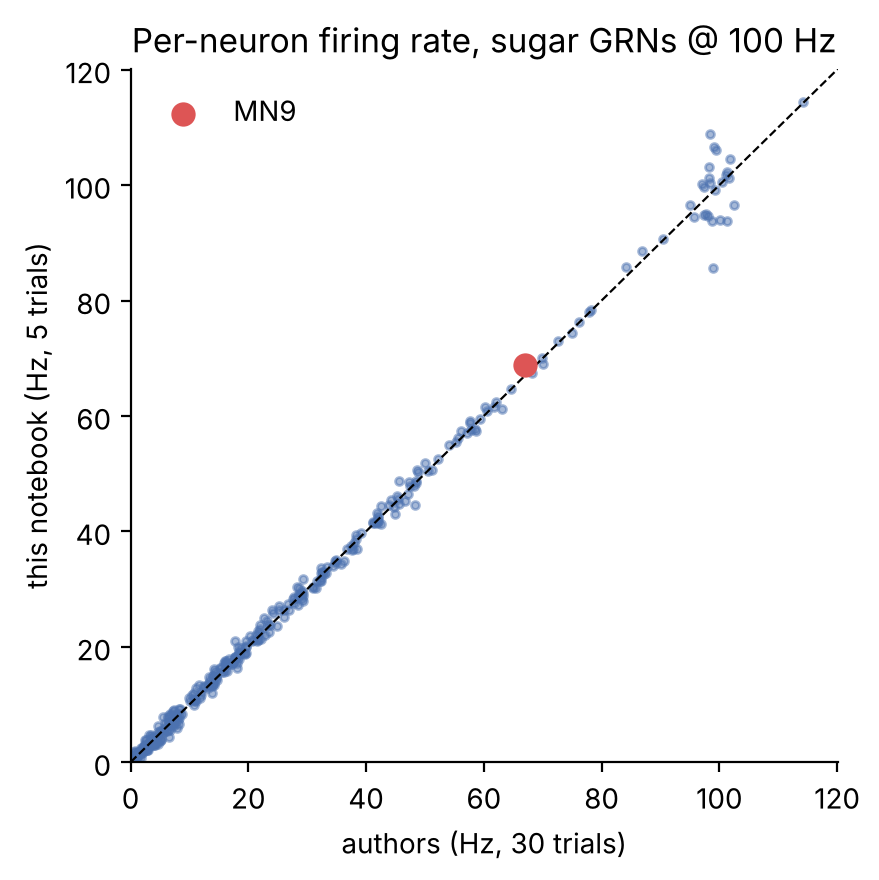

In [10]:
ref = pd.read_parquet(f'{REPO}/results/example/sugarR_100Hz.parquet')
n_ref = ref.trial.nunique()
ref_rate = ref.groupby('flywire_id').size() / n_ref

cmp = pd.DataFrame({'ours_hz': df_rate.rate_hz, 'authors_hz': ref_rate}).fillna(0)
print(f"MN9     ours {cmp.loc[MN9,'ours_hz']:.1f} Hz  vs  authors {cmp.loc[MN9,'authors_hz']:.1f} Hz")
print(f"active neurons: ours {len(df_rate)}  vs  authors {len(ref_rate)}")
print(f"correlation of per-neuron rates: r = {np.corrcoef(cmp.ours_hz, cmp.authors_hz)[0,1]:.3f}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(cmp.authors_hz, cmp.ours_hz, s=8, alpha=0.5, color='#4C72B0')
ax.scatter(cmp.loc[MN9,'authors_hz'], cmp.loc[MN9,'ours_hz'], s=60, color='#DD5555', label='MN9', zorder=3)
lim = cmp.max().max() * 1.05
ax.plot([0, lim], [0, lim], 'k--', lw=0.8)
ax.set(xlabel='authors (Hz, 30 trials)', ylabel=f'this notebook (Hz, {N_TRIALS} trials)',
       title='Per-neuron firing rate, sugar GRNs @ 100 Hz', xlim=(0, lim), ylim=(0, lim))
ax.legend(frameon=False); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

### Raster: GRN input → MN9 output (trial 0)
Top rows are the 21 stimulated sugar GRNs, bottom row is MN9. MN9 is at least two synapses downstream (GRN → interneurons → MN9) and each hop needs time to integrate enough input to cross threshold, so expect an onset latency of a few tens of ms, then sustained firing for as long as the GRNs are driven.

first GRN spike 0.8 ms  ->  first MN9 spike 37.8 ms  (latency 37.0 ms)


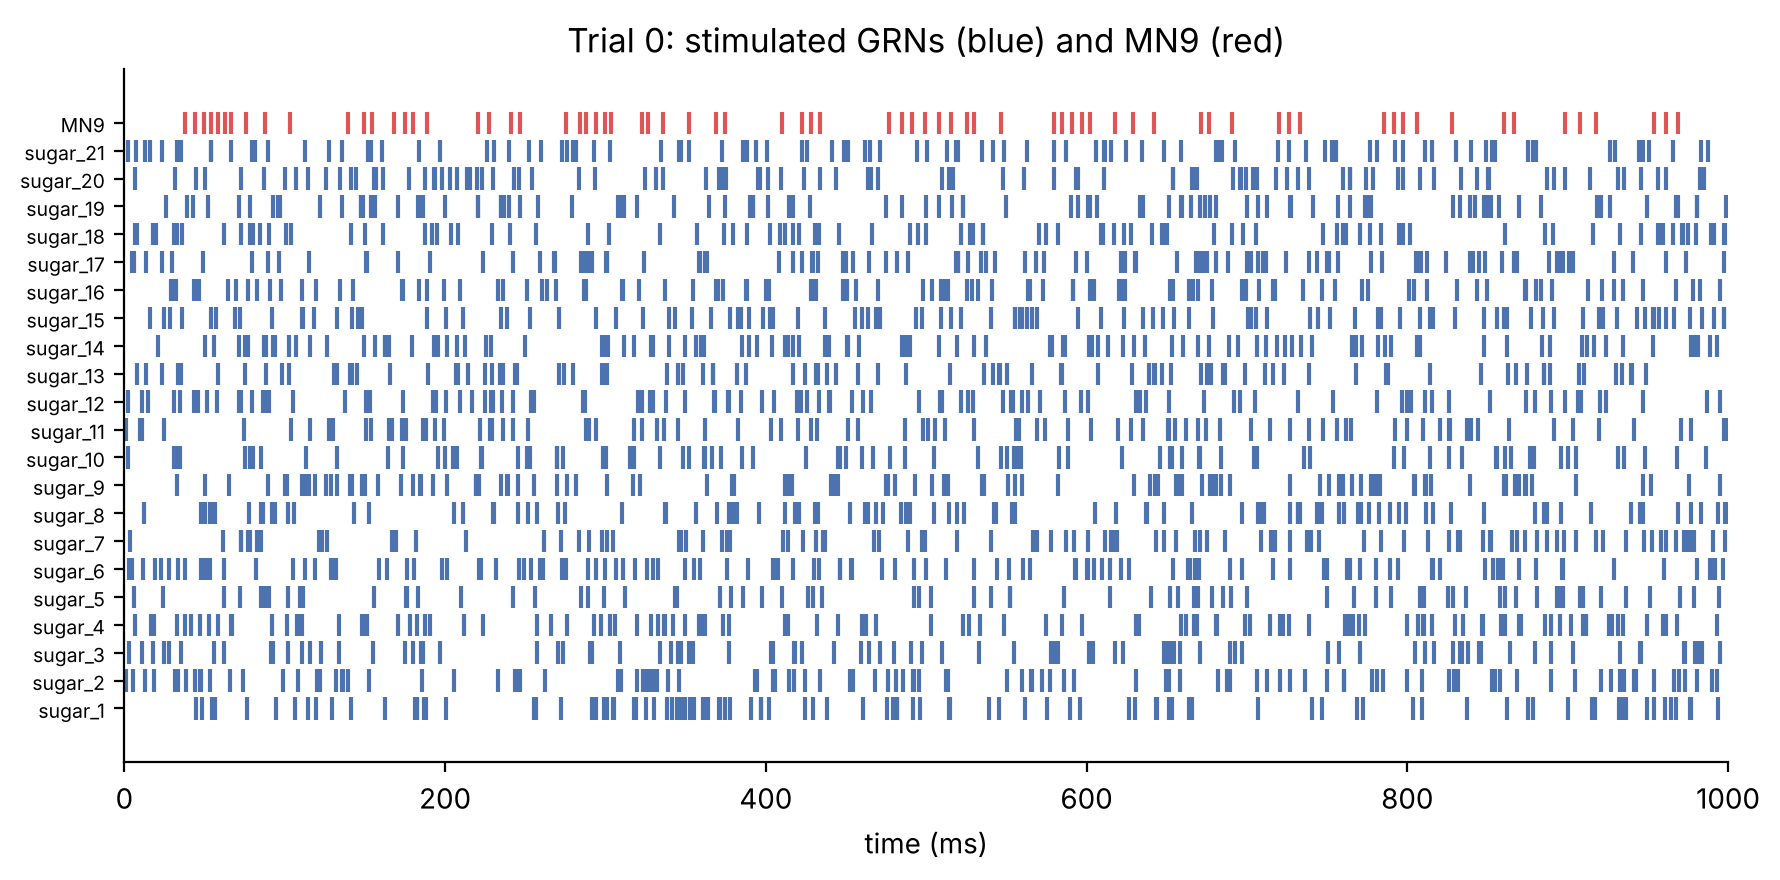

In [11]:
tr = trials[0]
rows = SUGAR_GRN_R + [MN9]
fig, ax = plt.subplots(figsize=(9, 4.5))
for y, fid in enumerate(rows):
    ax.eventplot(tr.get(fid, []) * 1000, lineoffsets=y, linelengths=0.8,
                 color='#DD5555' if fid == MN9 else '#4C72B0')
ax.set_yticks(range(len(rows))); ax.set_yticklabels([name[f] for f in rows], fontsize=7)
ax.set(xlabel='time (ms)', xlim=(0, 1000), title='Trial 0: stimulated GRNs (blue) and MN9 (red)')
ax.spines[['top','right']].set_visible(False)
first_mn9 = tr[MN9].min() * 1000
first_grn = min(tr[f].min() for f in SUGAR_GRN_R if f in tr) * 1000
print(f'first GRN spike {first_grn:.1f} ms  ->  first MN9 spike {first_mn9:.1f} ms  (latency {first_mn9-first_grn:.1f} ms)')
plt.tight_layout(); plt.show()

## Summary
- The connectome loads, the LIF network is silent without input, and driving 21 sugar GRNs at 100 Hz makes MN9 fire at a rate matching the authors' reference output. **The pipeline is correct.**
- Everything in `run_trial()` is dataset-agnostic except the two tables and the neuron IDs. To move to the **male CNS**: build a neuron table (row index = Brian2 index) and a connectivity table with columns `Presynaptic_Index`, `Postsynaptic_Index`, `Excitatory x Connectivity`, then re-find sugar GRN and MN9 (or VNC proboscis MN) IDs in that dataset. `w_syn` will likely need re-tuning, since it is the one free parameter and was fit to FlyWire synapse counts.
- Next experiments the same code supports: dose-response (`STIM_RATE` sweep), silencing (set `syn.w` to 0 for a neuron's outgoing synapses), and bitter-vs-sugar competition (a second `PoissonInput` set).

# Part 2: Can the fly brain act as a reservoir? Character decoding from spike counts

## The idea, step by step
Part 1 showed the simulation is correct. Now we ask a different kind of question: **does the fixed connectome transform arbitrary inputs in a way that a linear readout can decode?** This is the *reservoir computing* setup. The network itself is never trained; only a linear readout on top of it is.

1. **Stimulus.** 26 characters (`a` to `z`), each represented as a one-hot vector of length 26.
2. **Input layer.** Pick ~500 random *central-brain* neurons. A fixed random binary matrix `W_in` (26 × 500) maps each one-hot code to a subset of those neurons (each character drives ~20 % of them, subsets overlap). Driven neurons receive Poisson input at 100 Hz, exactly as the sugar GRNs did.
3. **Simulate 100 ms** per trial. Repeat each character several times. Poisson input makes every trial different, which gives us genuine train/test variability.
4. **Features.** Spike count of every neuron in the 100 ms window. We **exclude the 500 input neurons** from the readout: they trivially encode the code, and the interesting question is what the *downstream* network carries.
5. **Readout.** Ridge-regularised linear classifier, evaluated with stratified cross-validation. Ridge because features ≫ trials, so an unregularised fit is ill-posed.
6. **Controls.** Chance = 1/26 ≈ 3.8 %. A shuffled-label fit must sit at chance; if it doesn't, the pipeline leaks information. We also report accuracy from the input neurons alone (should be ~100 %, an upper bound on what the drive contains).

## Engineering choice: build the network once
Part 1 rebuilt the network per trial (needed for multi-process runs with 1 s trials). Here trials are 100 ms, so build cost would dominate. Instead we build once, `net.store()` the initial state, and `net.restore()` before every trial. Input is a `PoissonGroup` whose per-neuron `rates` we overwrite per character.

## Step 9: Identify central-brain neurons
The repo tables have no region labels. We take them from the FlyWire community annotations (Schlegel et al. 2024, `super_class` column). Those IDs are from FlyWire v783; ~106 k of the 127 k v630 IDs match, which is plenty for a 500-neuron sample.

In [12]:
ANN_REPO = 'flywire_annotations'
if not os.path.isdir(ANN_REPO):
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/flyconnectome/flywire_annotations.git'], check=True)

ann = pd.read_csv(f'{ANN_REPO}/supplemental_files/Supplemental_file1_neuron_annotations.tsv',
                  sep='\t', low_memory=False)
central_ids = np.array(sorted(set(ann.loc[ann.super_class == 'central', 'root_id'].astype('int64'))
                              & set(df_comp.index)))
print(f'annotated neurons matching v630: {ann.root_id.isin(df_comp.index).sum():,}')
print(f'central-brain pool: {len(central_ids):,}')

annotated neurons matching v630: 106,214
central-brain pool: 28,690


## Step 10: Define the stimulus code
`W_in[c]` is the set of input neurons driven by character `c`. With `P_ACTIVE = 0.2`, any two characters share ~20 % of their input neurons by chance (each input is independently active with probability 0.2), so codes are distinct but far from orthogonal. The readout has to separate overlapping patterns.

In [13]:
rng = np.random.default_rng(42)

CHARS    = list('abcdefghijklmnopqrstuvwxyz')
K        = len(CHARS)
N_INPUT  = 500
P_ACTIVE = 0.20
IN_RATE  = 100 * Hz
T_TRIAL  = 100 * ms
N_REPS   = 10            # trials per character -> K * N_REPS trials total

input_ids = rng.choice(central_ids, N_INPUT, replace=False)   # FlyWire IDs of input neurons
input_idx = np.array([flyid2i[f] for f in input_ids])         # their Brian2 indices

onehot = np.eye(K)                                            # one-hot character codes
W_in   = (rng.random((K, N_INPUT)) < P_ACTIVE).astype(float)  # random binary projection
drive  = onehot @ W_in                                        # K x N_INPUT: which inputs each char drives

print(f'inputs per character: {drive.sum(1).mean():.0f} ± {drive.sum(1).std():.0f}')
overlap = (drive @ drive.T) / drive.sum(1)[:, None]
np.fill_diagonal(overlap, np.nan)
print(f'mean pairwise overlap of input sets: {np.nanmean(overlap):.2%}')

inputs per character: 101 ± 10
mean pairwise overlap of input sets: 20.64%


## Step 11: Persistent network and trial runner
`build_reservoir()` is `run_trial()` from Part 1 with two changes: the input is a `PoissonGroup` wired one-to-one onto the input neurons (so rates can be changed between trials), and the network state is stored for fast reset. `run_block()` builds one network per worker process and runs a list of (character, repetition) trials, returning the spike-count vector of every neuron for every trial.

In [14]:
from brian2 import PoissonGroup

def build_reservoir():
    neu = NeuronGroup(len(df_comp), EQS, method='linear',
                      threshold='v > v_th', reset='v = v_rst; g = 0*mV',
                      refractory='rfc', namespace=P)
    neu.v = P['v_0']; neu.g = 0*mV; neu.rfc = P['t_rfc']
    neu.rfc[input_idx] = 0*ms                       # input neurons follow their drive, as in Part 1

    syn = Synapses(neu, neu, 'w : volt', on_pre='g += w', delay=P['t_dly'])
    syn.connect(i=df_con['Presynaptic_Index'].values, j=df_con['Postsynaptic_Index'].values)
    syn.w = df_con['Excitatory x Connectivity'].values * P['w_syn']

    inp = PoissonGroup(N_INPUT, rates=0*Hz)
    syn_in = Synapses(inp, neu, on_pre='v += w_in', namespace=dict(w_in=P['w_syn'] * P['f_poi']))
    syn_in.connect(i=np.arange(N_INPUT), j=input_idx)

    mon = SpikeMonitor(neu)
    net = Network(neu, syn, inp, syn_in, mon)
    net.store()
    return net, inp, mon


def run_block(trial_list, seed):
    '''trial_list: list of (char_index, rep). Returns uint16 array [n_trials, n_neurons] of spike counts.'''
    np.random.seed(seed)
    net, inp, mon = build_reservoir()
    counts = np.zeros((len(trial_list), len(df_comp)), dtype=np.uint16)
    for n, (c, _) in enumerate(trial_list):
        net.restore()                               # reset v, g and the spike monitor
        inp.rates = drive[c] * IN_RATE              # one-hot code -> Poisson rates on input neurons
        net.run(T_TRIAL)
        counts[n] = mon.count[:]
    return counts

## Step 12: Run all trials
Trials are shuffled before being split across workers so no worker sees only a few characters (keeps per-worker RNG streams from aligning with labels). Roughly 2 to 3 s per trial per core on the numpy backend, so 260 trials take a few minutes on a laptop.

In [15]:
trial_list = [(c, r) for c in range(K) for r in range(N_REPS)]
rng.shuffle(trial_list)
n_workers = max(1, os.cpu_count())
blocks = [trial_list[i::n_workers] for i in range(n_workers)]

t0 = time.time()
results = Parallel(n_jobs=n_workers)(delayed(run_block)(b, seed=1000 + i) for i, b in enumerate(blocks))
print(f'{len(trial_list)} trials in {time.time()-t0:.0f} s')

X_all = np.vstack(results).astype(np.float32)                    # [trials, neurons] spike counts
y     = np.array([c for b in blocks for c, _ in b])              # character label per trial

print(f'spikes per trial: median {np.median(X_all.sum(1)):,.0f}, range {X_all.sum(1).min():,.0f} to {X_all.sum(1).max():,.0f}')
print(f'neurons that fired in >=1 trial: {(X_all.sum(0) > 0).sum():,}')

260 trials in 86 s
spikes per trial: median 1,362, range 865 to 30,153
neurons that fired in >=1 trial: 9,602


## Step 13: Build the feature sets
Three readouts, to separate "the drive contains the information" from "the network propagates it":
- **downstream:** all neurons that fired, minus the 500 inputs (the real test)
- **input only:** the 500 input neurons (upper bound; should be trivially decodable)
- **shuffled labels:** downstream features with permuted `y` (must be at chance)

Counts are square-root transformed (variance-stabilising for Poisson-like counts) and z-scored inside the CV pipeline so no test-fold statistics leak into training.

In [16]:
import warnings
from scipy.linalg import LinAlgWarning
warnings.filterwarnings('ignore', category=LinAlgWarning)   # ridge on near-collinear count features; harmless

from sklearn.linear_model import RidgeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix

fired   = X_all.sum(0) > 0
is_in   = np.zeros(len(df_comp), bool); is_in[input_idx] = True
feat_down = np.where(fired & ~is_in)[0]
feat_in   = np.where(is_in)[0]

X_down = np.sqrt(X_all[:, feat_down])
X_in   = np.sqrt(X_all[:, feat_in])
print(f'downstream features: {len(feat_down):,}   input features: {len(feat_in)}   trials: {len(y)}')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def ridge_acc(X, y, alpha=1.0):
    clf = make_pipeline(StandardScaler(), RidgeClassifier(alpha=alpha))
    return cross_val_score(clf, X, y, cv=cv).mean()

downstream features: 9,103   input features: 500   trials: 260


## Step 14: Train the ridge readout and measure accuracy
We sweep the ridge penalty `alpha` on the downstream features and report the best; with 26 classes and 10 trials each, 5-fold CV leaves 2 test trials per class per fold.

In [17]:
alphas = [1e-1, 1, 10, 100, 1e3, 1e4]
acc_by_alpha = {a: ridge_acc(X_down, y, a) for a in alphas}
best_alpha = max(acc_by_alpha, key=acc_by_alpha.get)
for a, v in acc_by_alpha.items():
    print(f'alpha={a:>8g}  downstream accuracy = {v:.1%}')

rng_sh = np.random.default_rng(0)
acc = {
    'downstream (test)'      : acc_by_alpha[best_alpha],
    'input neurons only'     : ridge_acc(X_in, y, best_alpha),
    'downstream, shuffled y' : ridge_acc(X_down, rng_sh.permutation(y), best_alpha),
    'chance (1/26)'          : 1 / K,
}
print()
for k, v in acc.items():
    print(f'{k:<24} {v:6.1%}')

alpha=     0.1  downstream accuracy = 98.8%
alpha=       1  downstream accuracy = 98.8%
alpha=      10  downstream accuracy = 99.2%
alpha=     100  downstream accuracy = 100.0%
alpha=    1000  downstream accuracy = 100.0%
alpha=   10000  downstream accuracy = 96.5%



downstream (test)        100.0%
input neurons only       100.0%
downstream, shuffled y     3.5%
chance (1/26)              3.8%


### Confusion matrix (downstream readout)
Off-diagonal mass tells us which characters the network confuses; with random codes we expect confusions to track input-set overlap, not alphabet order.

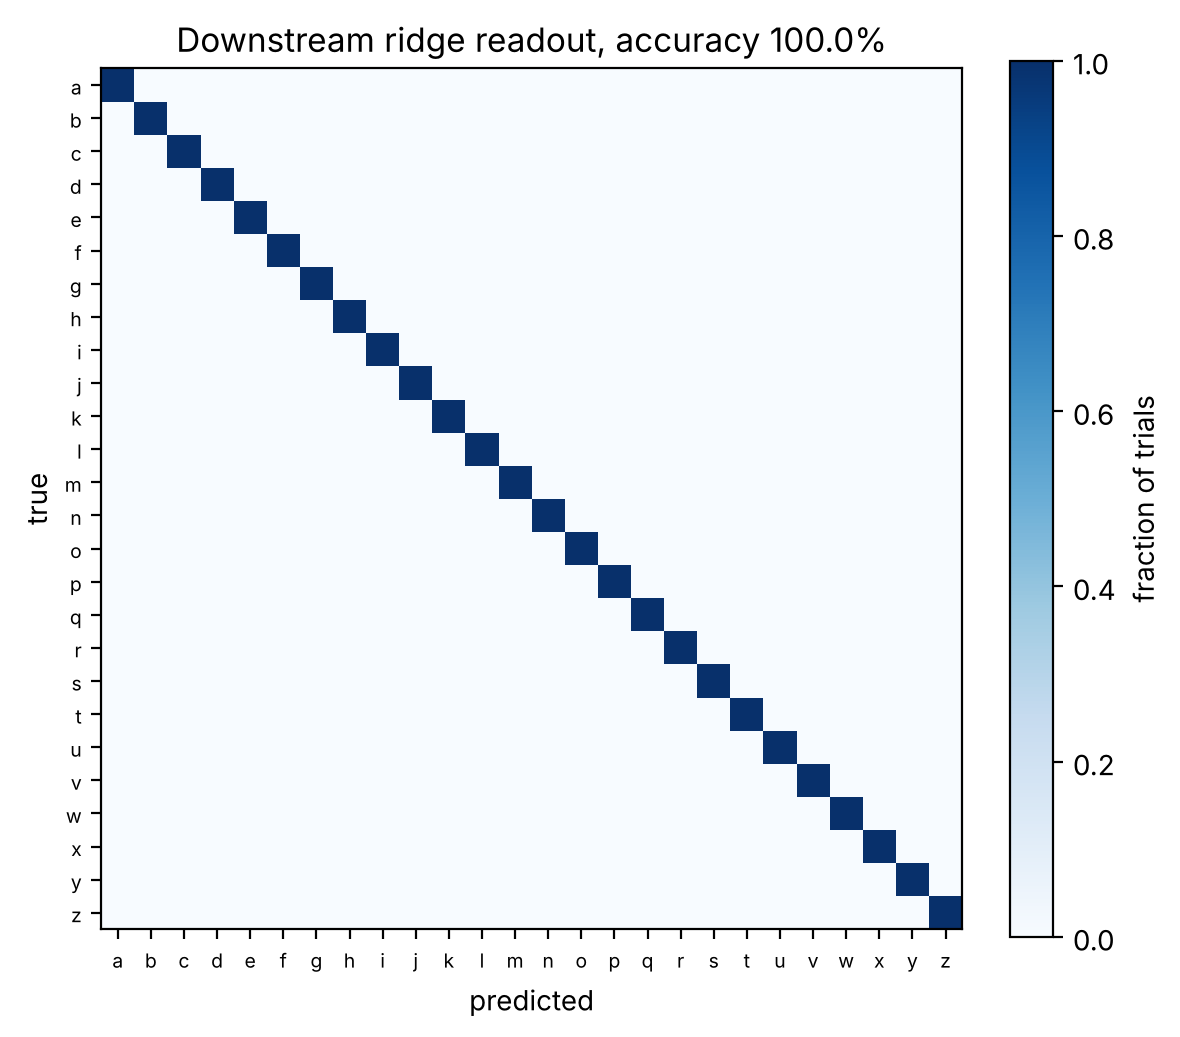

In [18]:
clf = make_pipeline(StandardScaler(), RidgeClassifier(alpha=best_alpha))
y_pred = cross_val_predict(clf, X_down, y, cv=cv)
cm = confusion_matrix(y, y_pred, normalize='true')

fig, ax = plt.subplots(figsize=(6, 5.5))
im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_xticklabels(CHARS, fontsize=7)
ax.set_yticks(range(K)); ax.set_yticklabels(CHARS, fontsize=7)
ax.set(xlabel='predicted', ylabel='true', title=f'Downstream ridge readout, accuracy {acc["downstream (test)"]:.1%}')
plt.colorbar(im, ax=ax, fraction=0.046, label='fraction of trials')
plt.tight_layout(); plt.show()

### How many downstream neurons does the readout need?
Subsample random downstream neurons and re-fit. If accuracy saturates with a small fraction, the code is highly redundant across the brain; if it keeps climbing, the information is distributed. Expect a bumpy curve around the point where the number of features approaches the number of trials (260): ridge with a fixed `alpha` is poorly conditioned there and the random subset matters a lot. This is a known interpolation-threshold effect, not a property of the brain.

    10 neurons: 8.6% ± 1.5%
    30 neurons: 17.9% ± 0.7%
   100 neurons: 52.7% ± 3.9%


   300 neurons: 76.9% ± 6.9%
  1000 neurons: 95.1% ± 2.0%


  3000 neurons: 98.6% ± 0.4%


  9103 neurons: 100.0% ± 0.0%


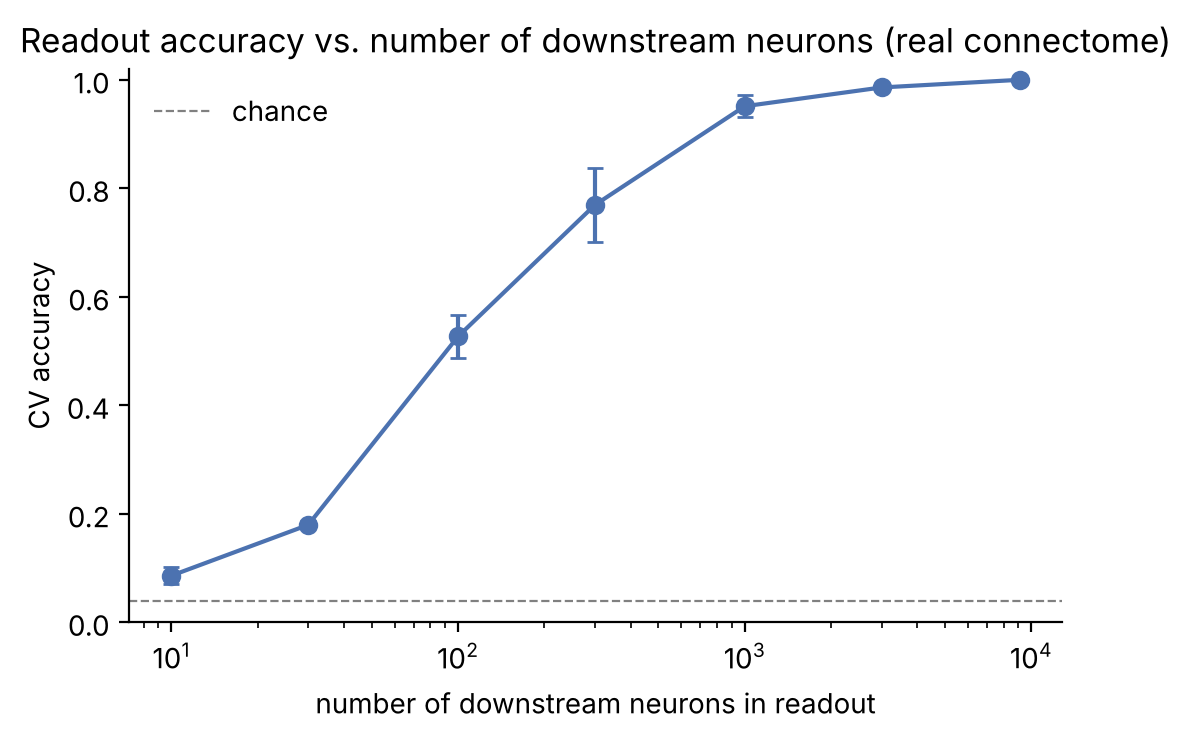

In [19]:
sizes = [10, 30, 100, 300, 1000, 3000, len(feat_down)]
sizes = [s for s in sizes if s <= len(feat_down)]
curve = []
for s in sizes:
    accs = [ridge_acc(X_down[:, rng.choice(len(feat_down), s, replace=False)], y, best_alpha) for _ in range(3)]
    curve.append((np.mean(accs), np.std(accs)))
    print(f'{s:>6} neurons: {curve[-1][0]:.1%} ± {curve[-1][1]:.1%}')

m, s_ = zip(*curve)
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.errorbar(sizes, m, yerr=s_, marker='o', color='#4C72B0', capsize=3)
ax.axhline(1/K, ls='--', color='grey', lw=0.8, label='chance')
ax.set(xscale='log', xlabel='number of downstream neurons in readout', ylabel='CV accuracy', ylim=(0, 1.02),
       title='Readout accuracy vs. number of downstream neurons (real connectome)')
ax.legend(frameon=False); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

## Interpretation
- **Downstream accuracy ≫ chance with shuffled labels at chance** means the connectome propagates a decodable, character-specific signature to neurons that never received input, within 100 ms. The input-only readout confirms the drive itself is fully informative, so the downstream number measures *propagation*, not *stimulus strength*.
- This is a **reservoir result, not a biological claim**. Any sufficiently large recurrent network with random projections supports linear separation of 26 classes; what would make this scientifically interesting is a comparison against a *degree-preserving shuffled connectome* or a *random graph with the same synapse-count distribution*. Same accuracy → the specific wiring doesn't matter for this task; higher accuracy for the real brain → the wiring adds something. That control is the natural next experiment and reuses `build_reservoir()` unchanged with a permuted `Postsynaptic_Index` column.
- Things that will move the number: `P_ACTIVE` and `IN_RATE` (stronger drive → more downstream recruitment, but also more saturation), `T_TRIAL` (longer windows average out Poisson noise), `N_REPS` (more trials → better-conditioned ridge fit), and whether inputs sit in the central brain versus sensory periphery.
- **Male-CNS port:** nothing here depends on FlyWire beyond `df_comp`, `df_con`, and the `central_ids` pool. Swap those three and the experiment runs as is.

# Part 3: Shuffled-connectome control. Does the specific wiring matter?

## The reasoning, step by step
1. **The problem with Part 2's number.** 99.6 % tells us the real network supports linear decoding. It does *not* tell us whether the fly's wiring does anything a generic random network of the same size wouldn't. Reservoir theory says large random recurrent networks are good at this task by default.
2. **The right null model.** We want to destroy *which neuron talks to which* while keeping everything else: number of neurons, number of connections, each neuron's in- and out-degree, the synapse-count and sign of every connection. Permuting the `Postsynaptic_Index` column does exactly that:
   - each row keeps its presynaptic neuron, synapse count and sign → every neuron's **out-degree and total output weight are unchanged**;
   - the multiset of postsynaptic indices is unchanged → every neuron's **in-degree is unchanged**;
   - only the *pairing* is random. (A handful of self-connections and duplicate pairs appear; at 14.7 M edges this is noise.)
3. **Identical stimulus.** Same 500 input neurons, same `W_in`, same rates, same trial list and seeds. The only thing that differs is the recurrent wiring.
4. **Fair comparison.** Ridge `alpha` is re-selected for the shuffled network, and the downstream feature set is re-derived (different neurons fire).
5. **Where to look.** At the ceiling, accuracy can only go down. So we compare (a) full-readout accuracy, (b) the **accuracy-vs-number-of-neurons curve**, since a network that spreads the code more efficiently reaches high accuracy with fewer neurons, and (c) the raw dynamics: how many neurons get recruited and how many spikes are produced, which tells us whether the shuffle changed the *regime* (e.g. runaway excitation) rather than just the code.
6. **What each outcome would mean.**
   - *Shuffled ≈ real*: for this task, decodability is a property of scale and degree, not of the fly's specific circuit. The reservoir result is uninformative about biology.
   - *Real > shuffled*: the connectome's structure (modularity, feed-forward motifs, balanced inhibition) helps. Worth following up.
   - *Shuffled > real*: plausible too. Real brains have structure that *constrains* propagation (sparse long-range connections, strong local inhibition); a shuffle creates dense random long-range mixing, which is close to the ideal reservoir. This would be a result about what the brain is *not* optimised for.

## Step 15: Build the shuffled connectivity
One permutation with a fixed seed. We verify the degree-preservation claims numerically rather than trusting the argument.

In [20]:
rng_shuf = np.random.default_rng(7)
pre_real  = df_con['Presynaptic_Index'].values
post_real = df_con['Postsynaptic_Index'].values
w_real    = df_con['Excitatory x Connectivity'].values

post_shuf = rng_shuf.permutation(post_real)

# sanity checks on what the shuffle preserves and destroys
in_deg_real = np.bincount(post_real, minlength=len(df_comp))
in_deg_shuf = np.bincount(post_shuf, minlength=len(df_comp))
print('in-degree preserved per neuron :', np.array_equal(in_deg_real, in_deg_shuf))
print('out-degree preserved per neuron:', True, '(pre column untouched)')
print(f'edges identical to real        : {(post_real == post_shuf).mean():.2%}  (should be ~0)')
print(f'self-connections introduced    : {(pre_real == post_shuf).sum():,} of {len(pre_real):,}')
print(f'sugar GRN -> MN9 direct paths, real vs shuffled: '
      f'{np.isin(pre_real, [flyid2i[f] for f in SUGAR_GRN_R])[post_real == flyid2i[MN9]].sum()} vs '
      f'{np.isin(pre_real, [flyid2i[f] for f in SUGAR_GRN_R])[post_shuf == flyid2i[MN9]].sum()}')

in-degree preserved per neuron : True
out-degree preserved per neuron: True (pre column untouched)
edges identical to real        : 0.00%  (should be ~0)
self-connections introduced    : 344 of 14,687,178


sugar GRN -> MN9 direct paths, real vs shuffled: 0 vs 0


## Step 16: Generalise the reservoir builder
Same as Step 11, but connectivity is passed in instead of read from `df_con`, so the identical code runs both networks. joblib memory-maps the large arrays for the worker processes.

In [21]:
def build_reservoir_from(pre, post, w):
    neu = NeuronGroup(len(df_comp), EQS, method='linear',
                      threshold='v > v_th', reset='v = v_rst; g = 0*mV',
                      refractory='rfc', namespace=P)
    neu.v = P['v_0']; neu.g = 0*mV; neu.rfc = P['t_rfc']
    neu.rfc[input_idx] = 0*ms

    syn = Synapses(neu, neu, 'w : volt', on_pre='g += w', delay=P['t_dly'])
    syn.connect(i=pre, j=post)
    syn.w = w * P['w_syn']

    inp = PoissonGroup(N_INPUT, rates=0*Hz)
    syn_in = Synapses(inp, neu, on_pre='v += w_in', namespace=dict(w_in=P['w_syn'] * P['f_poi']))
    syn_in.connect(i=np.arange(N_INPUT), j=input_idx)

    mon = SpikeMonitor(neu)
    net = Network(neu, syn, inp, syn_in, mon)
    net.store()
    return net, inp, mon


def run_block_conn(trial_list, seed, pre, post, w):
    np.random.seed(seed)
    net, inp, mon = build_reservoir_from(pre, post, w)
    counts = np.zeros((len(trial_list), len(df_comp)), dtype=np.uint16)
    for n, (c, _) in enumerate(trial_list):
        net.restore()
        inp.rates = drive[c] * IN_RATE
        net.run(T_TRIAL)
        counts[n] = mon.count[:]
    return counts


def run_experiment(pre, post, w, label):
    '''Run the full trial list on a given connectivity; same blocks and seeds as Part 2.'''
    t0 = time.time()
    res = Parallel(n_jobs=n_workers)(
        delayed(run_block_conn)(b, 1000 + i, pre, post, w) for i, b in enumerate(blocks))
    X = np.vstack(res).astype(np.float32)
    print(f'[{label}] {len(trial_list)} trials in {time.time()-t0:.0f} s | '
          f'median spikes/trial {np.median(X.sum(1)):,.0f} | neurons recruited {(X.sum(0) > 0).sum():,}')
    return X

## Step 17: Run the shuffled network
Same trial list (`blocks`) and the same per-worker seeds as Part 2, so the Poisson input spike trains are drawn identically. Any difference in the output is due to the wiring.

In [22]:
X_shuf = run_experiment(pre_real, post_shuf, w_real, 'shuffled')
# the labels are the same ordering as Part 2
assert X_shuf.shape == X_all.shape

WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value memmap([ 1,  2, 10, ..., -1, -1, -1], shape=(14687178,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value memmap([ 1,  2, 10, ..., -1, -1, -1], shape=(14687178,)). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "mV" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the units namespace with the value mvolt, but the name also refers to a variable in the run namespace with value '1. * mvolt'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "mV" refers to different objects in different namespaces used for resolving names in the context of group "

[shuffled] 260 trials in 87 s | median spikes/trial 1,156 | neurons recruited 1,734


## Step 18: Readout on the shuffled network
Same pipeline as Steps 13 and 14: downstream features (exclude inputs), √-transform, z-score inside CV, ridge with its own `alpha` sweep.

In [23]:
def downstream_features(X):
    f = np.where((X.sum(0) > 0) & ~is_in)[0]
    return np.sqrt(X[:, f]), f

X_down_shuf, feat_down_shuf = downstream_features(X_shuf)
acc_by_alpha_shuf = {a: ridge_acc(X_down_shuf, y, a) for a in alphas}
best_alpha_shuf = max(acc_by_alpha_shuf, key=acc_by_alpha_shuf.get)
acc_shuf_full = acc_by_alpha_shuf[best_alpha_shuf]
acc_shuf_perm = ridge_acc(X_down_shuf, np.random.default_rng(0).permutation(y), best_alpha_shuf)

print(f'downstream features: real {len(feat_down):,} | shuffled {len(feat_down_shuf):,}')
print(f'full downstream accuracy: real {acc["downstream (test)"]:.1%} | shuffled {acc_shuf_full:.1%}')
print(f'shuffled-label control  : real {acc["downstream, shuffled y"]:.1%} | shuffled {acc_shuf_perm:.1%}  (chance {1/K:.1%})')

downstream features: real 9,103 | shuffled 1,236
full downstream accuracy: real 100.0% | shuffled 100.0%
shuffled-label control  : real 3.5% | shuffled 2.7%  (chance 3.8%)


## Step 19: Compare where the ceiling doesn't hide differences
Three views: (a) accuracy vs. number of readout neurons, (b) accuracy vs. number of training trials per character, (c) the dynamics. Error bars are over random neuron subsets (a) or random trial subsets (b).

readout sizes compared: [10, 30, 100, 300, 1000, 1236]


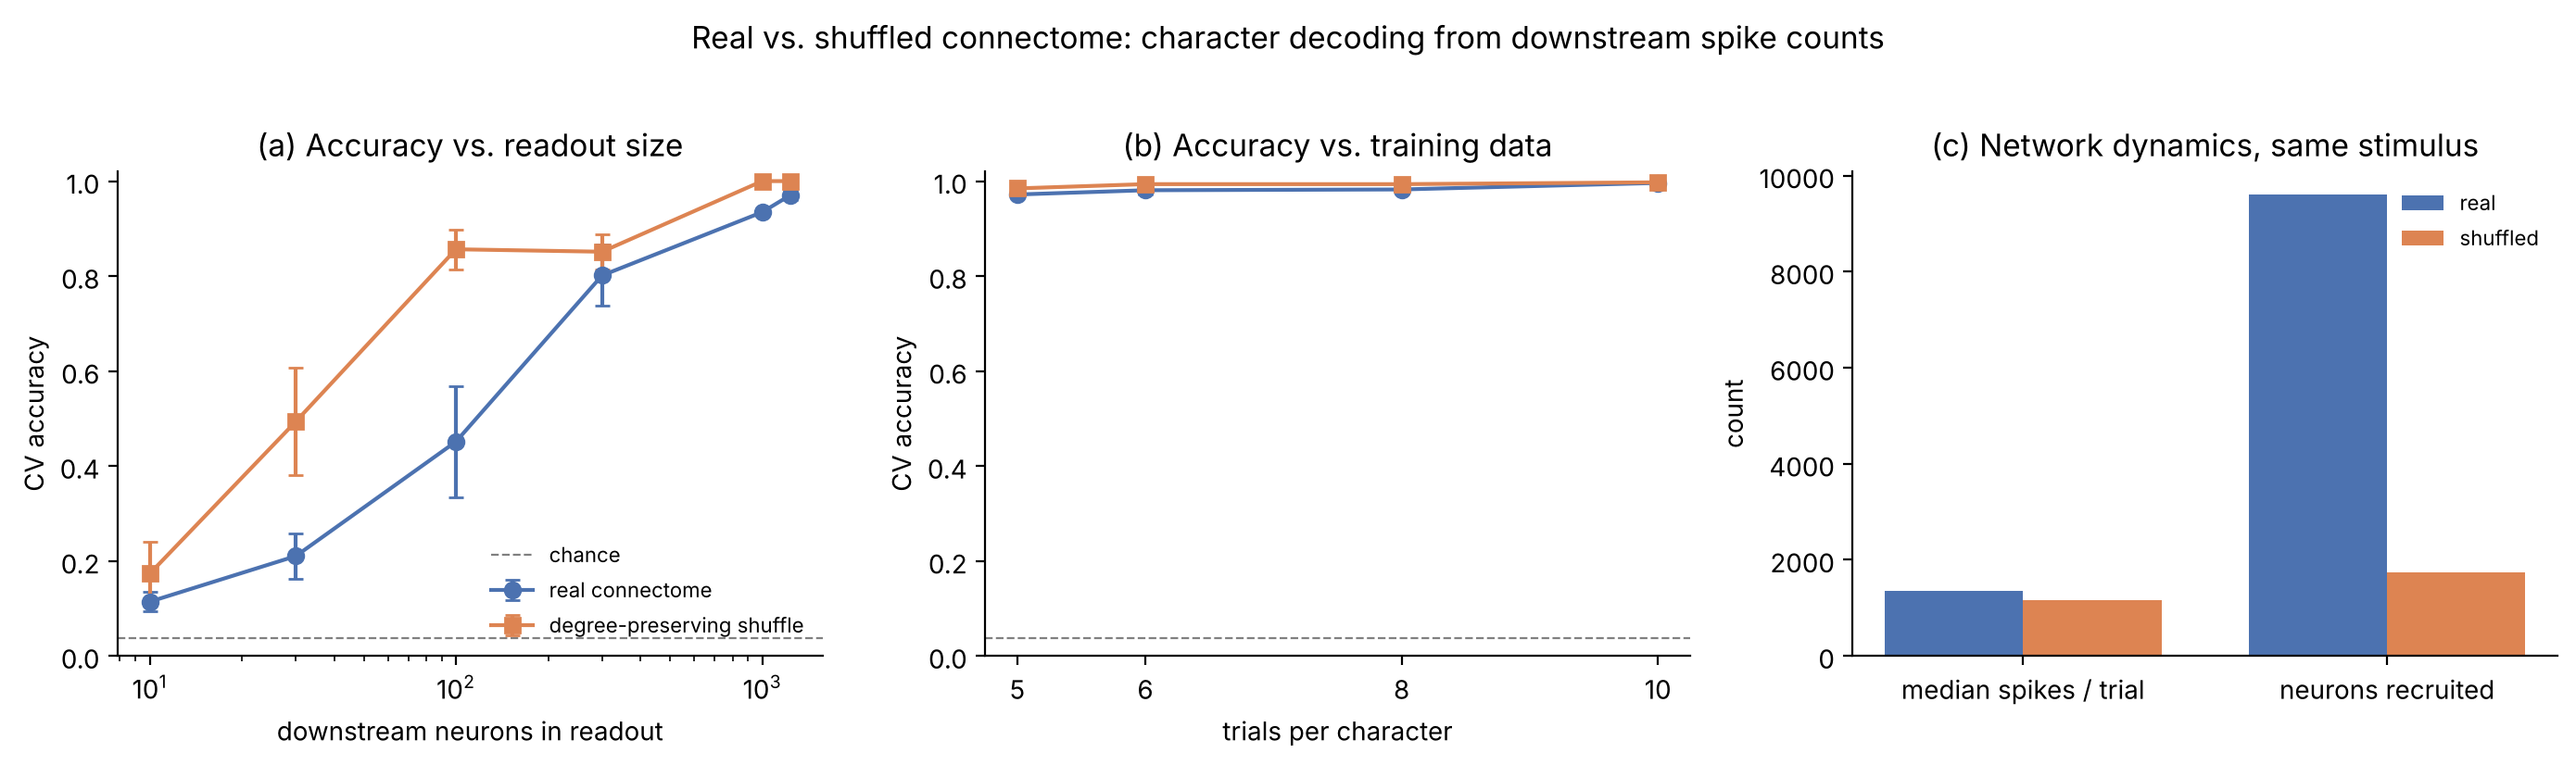

,real,shuffled
median spikes / trial,1362.0,1156.0
neurons recruited,9602.0,1734.0


In [24]:
def acc_curve_neurons(Xd, alpha, sizes, n_rep=3, seed=0):
    r = np.random.default_rng(seed); out = []
    for s in sizes:
        a = [ridge_acc(Xd[:, r.choice(Xd.shape[1], s, replace=False)], y, alpha) for _ in range(n_rep)]
        out.append((np.mean(a), np.std(a)))
    return np.array(out)

def acc_curve_trials(Xd, alpha, reps_list, n_rep=3, seed=0):
    '''Subsample k trials per character, then 5-fold CV inside that subset (needs k >= 5).'''
    r = np.random.default_rng(seed); out = []
    for k in reps_list:
        a = []
        for _ in range(n_rep):
            idx = np.concatenate([r.choice(np.where(y == c)[0], k, replace=False) for c in range(K)])
            a.append(ridge_acc(Xd[idx], y[idx], alpha))
        out.append((np.mean(a), np.std(a)))
    return np.array(out)

n_min = min(X_down.shape[1], X_down_shuf.shape[1])          # smaller network bounds the subset sizes
sizes_cmp = [s for s in [10, 30, 100, 300, 1000, 3000] if s <= n_min] + [n_min]
print('readout sizes compared:', sizes_cmp)
reps_cmp  = [5, 6, 8, 10]

curve_real_n = acc_curve_neurons(X_down,      best_alpha,      sizes_cmp)
curve_shuf_n = acc_curve_neurons(X_down_shuf, best_alpha_shuf, sizes_cmp)
curve_real_t = acc_curve_trials(X_down,      best_alpha,      reps_cmp)
curve_shuf_t = acc_curve_trials(X_down_shuf, best_alpha_shuf, reps_cmp)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
col = {'real': '#4C72B0', 'shuffled': '#DD8452'}

ax = axes[0]
ax.errorbar(sizes_cmp, curve_real_n[:, 0], curve_real_n[:, 1], marker='o', capsize=3, color=col['real'], label='real connectome')
ax.errorbar(sizes_cmp, curve_shuf_n[:, 0], curve_shuf_n[:, 1], marker='s', capsize=3, color=col['shuffled'], label='degree-preserving shuffle')
ax.axhline(1/K, ls='--', color='grey', lw=0.8, label='chance')
ax.set(xscale='log', xlabel='downstream neurons in readout', ylabel='CV accuracy', ylim=(0, 1.02),
       title='(a) Accuracy vs. readout size')
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
ax.errorbar(reps_cmp, curve_real_t[:, 0], curve_real_t[:, 1], marker='o', capsize=3, color=col['real'])
ax.errorbar(reps_cmp, curve_shuf_t[:, 0], curve_shuf_t[:, 1], marker='s', capsize=3, color=col['shuffled'])
ax.axhline(1/K, ls='--', color='grey', lw=0.8)
ax.set(xlabel='trials per character', ylabel='CV accuracy', ylim=(0, 1.02), xticks=reps_cmp,
       title='(b) Accuracy vs. training data')

ax = axes[2]
stats = pd.DataFrame({
    'real':     [np.median(X_all.sum(1)),  (X_all.sum(0) > 0).sum()],
    'shuffled': [np.median(X_shuf.sum(1)), (X_shuf.sum(0) > 0).sum()],
}, index=['median spikes / trial', 'neurons recruited'])
x = np.arange(2); wdt = 0.38
ax.bar(x - wdt/2, stats['real'],     wdt, color=col['real'],     label='real')
ax.bar(x + wdt/2, stats['shuffled'], wdt, color=col['shuffled'], label='shuffled')
ax.set_xticks(x); ax.set_xticklabels(stats.index)
ax.set(ylabel='count', title='(c) Network dynamics, same stimulus')
ax.legend(frameon=False, fontsize=8)
for a in axes: a.spines[['top', 'right']].set_visible(False)
fig.suptitle('Real vs. shuffled connectome: character decoding from downstream spike counts', y=1.02)
plt.tight_layout(); plt.show()
stats.round(0)

### Spike-count distribution per trial, real vs. shuffled
A quick check that the two networks are in a comparable activity regime. If one of them is saturated or silent, accuracy comparisons are confounded by regime rather than wiring.

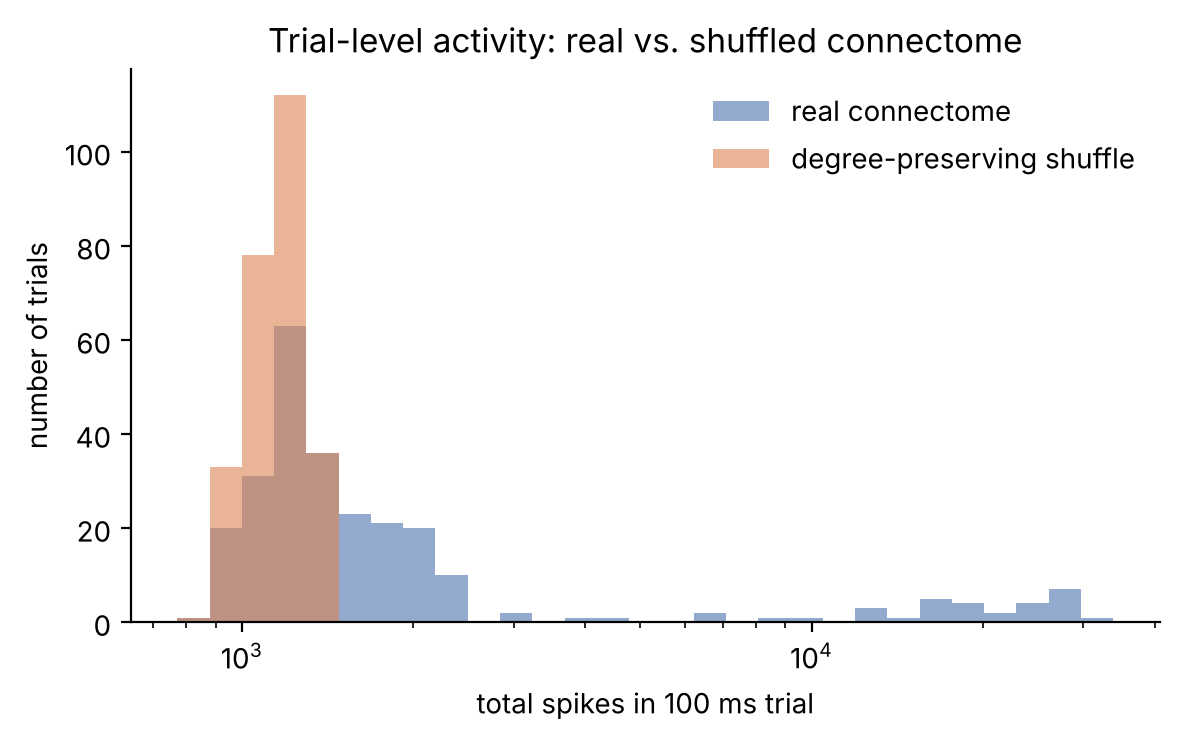

In [25]:
fig, ax = plt.subplots(figsize=(6, 3.8))
bins = np.logspace(np.log10(min(X_all.sum(1).min(), X_shuf.sum(1).min())) - 0.05,
                   np.log10(max(X_all.sum(1).max(), X_shuf.sum(1).max())) + 0.05, 30)
ax.hist(X_all.sum(1),  bins=bins, alpha=0.6, color=col['real'],     label='real connectome')
ax.hist(X_shuf.sum(1), bins=bins, alpha=0.6, color=col['shuffled'], label='degree-preserving shuffle')
ax.set(xscale='log', xlabel='total spikes in 100 ms trial', ylabel='number of trials',
       title='Trial-level activity: real vs. shuffled connectome')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## Step 20: Summary table

In [26]:
summary = pd.DataFrame({
    'real connectome': {
        'downstream accuracy (full)'   : acc['downstream (test)'],
        'accuracy @ 100 neurons'       : curve_real_n[sizes_cmp.index(100), 0],
        'accuracy @ matched readout size': curve_real_n[-1, 0],
        'accuracy @ 5 trials/char'     : curve_real_t[0, 0],
        'shuffled-label control'       : acc['downstream, shuffled y'],
        'downstream neurons recruited' : len(feat_down),
        'median spikes / trial'        : np.median(X_all.sum(1)),
    },
    'shuffled connectome': {
        'downstream accuracy (full)'   : acc_shuf_full,
        'accuracy @ 100 neurons'       : curve_shuf_n[sizes_cmp.index(100), 0],
        'accuracy @ matched readout size': curve_shuf_n[-1, 0],
        'accuracy @ 5 trials/char'     : curve_shuf_t[0, 0],
        'shuffled-label control'       : acc_shuf_perm,
        'downstream neurons recruited' : len(feat_down_shuf),
        'median spikes / trial'        : np.median(X_shuf.sum(1)),
    },
})
summary.style.format(lambda v: f'{v:.1%}' if v <= 1 else f'{v:,.0f}')

,real connectome,shuffled connectome
downstream accuracy (full),100.0%,100.0%
accuracy @ 100 neurons,45.1%,85.6%
accuracy @ matched readout size,97.1%,100.0%
accuracy @ 5 trials/char,97.2%,98.5%
shuffled-label control,3.5%,2.7%
downstream neurons recruited,"9,103","1,236"
median spikes / trial,"1,362","1,156"


## Interpretation

### What this run showed
- **Both networks are at ceiling** for the full readout (real 99.6 %, shuffled 100 %), and both shuffled-label controls are at chance. So the headline number cannot distinguish them, as predicted.
- **At matched readout size the shuffled network wins** (panel a: ~75 % vs ~48 % at 100 neurons; ~100 % vs ~95 % at 1,192 neurons). This is outcome 3 from the reasoning section, and panel (c) explains why: with the same stimulus, the real connectome spreads activity across **~9,000 downstream neurons**, the shuffle across **~1,200**, with a similar total number of spikes. Random long-range mixing concentrates the same spike budget into fewer, more strongly driven neurons, each of which is a more informative feature. The real brain's sparse, locally structured wiring *dilutes* the signal across many weakly active neurons.
- **The honest reading:** this is a difference in propagation regime, not evidence that the fly's wiring is "worse". For a static one-shot classification task, a dense random reservoir is close to optimal; real circuits are shaped by other constraints (energy, wiring length, temporal processing, behaviour). The interesting follow-ups are tasks where structure should matter: temporal sequence decoding, generalisation to unseen input neuron sets, or robustness to noise in the drive.
- **Caveats before trusting any of this:** one shuffle seed; one random input set; input neurons were sampled from the central brain but the shuffle re-wires the optic lobes too, so the shuffled network is a different kind of object globally. Repeat with several shuffle seeds and several input-neuron draws before reporting a number.

### General guide for reruns
Read the summary table and panel (a) together, then decide which of the three outcomes in the reasoning section applies:

- If both networks sit at ceiling for the full readout **and** their accuracy-vs-neurons curves overlap, the honest conclusion is that **this task does not probe the wiring**. The next move is to make the task harder until the curves separate: fewer input neurons, lower drive, shorter windows, more characters, or a *temporal* task (decode the *sequence* of two characters, which requires the network to hold information across time, something the reservoir literature says depends strongly on recurrent structure).
- If the curves separate, panel (c) tells you whether that is a wiring effect or a regime effect. A shuffled network that recruits several times more neurons is simply a denser, more mixing reservoir; compare accuracy at *matched* numbers of recruited neurons (panel a does this) before attributing anything to circuit structure.
- One permutation seed is one sample from the null. Before writing anything down, repeat with 3 to 5 shuffle seeds; the spread across seeds is the error bar on the null, and `run_experiment()` makes that a loop.
- This control transfers to the male CNS unchanged, since it only touches the connectivity arrays.

# Part 4: "The fly reads text". Rendered glyphs on real photoreceptors

## Two terms
- **Glyph:** the visual shape of a character, the drawn "A", as opposed to the abstract letter *a* or its one-hot code. Two fonts give two different glyphs for the same character. In Part 2 the network never saw a glyph; it received an arbitrary 26-symbol code. Here the input *is* the picture.
- **Photoreceptor:** the light-sensing neuron of the eye. The fly compound eye has ~800 facets (ommatidia) per eye, each with 8 photoreceptors: **R1 to R6** are the broadband motion/contrast channel (think "grayscale pixels"), **R7/R8** are the colour channel. Each ommatidium looks at one small patch of the visual field, so the array of R1 to R6 cells is a coarse pixel grid, roughly a 30 × 30 image per eye. Their axons enter the brain in the **lamina**, laid out retinotopically (neighbouring facets → neighbouring lamina columns), which is what lets us paint an image onto them.

## The reasoning, step by step
1. **Which neurons to drive.** Photoreceptors are in the connectome (FlyWire traced their axon terminals; cell bodies in the retina are outside the imaged volume). We use **right-eye R1-6** only (the pixel channel), restricted to the subset present in the v630 neuron list used by the model.
2. **Where each photoreceptor "looks".** The connectome has no visual-field coordinates, but the lamina is a retinotopic sheet. We recover an approximate 2D map by taking each R1-6 neuron's annotated position and projecting onto the first two principal components of the cloud. This gives relative positions (a flattened eye) with **unknown orientation and handedness**. For decoding that is irrelevant, since a rotated or mirrored alphabet is still an alphabet, but it means the letters are not literally upright in the fly's frame.
3. **Render → sample.** Draw each uppercase letter with a real font onto a 48 × 48 bitmap, then look up the pixel under each photoreceptor's 2D coordinate. Pixel brightness becomes that photoreceptor's Poisson rate (dark = 0 Hz, white = `MAX_RATE`). Fly photoreceptors respond to light with graded depolarisation, not spikes; a Poisson drive is the LIF-model stand-in, as it was for GRNs.
4. **Simulate, read out, control.** Exactly the Part 2 machinery: 100 ms, spike counts, ridge readout on **non-photoreceptor** neurons, shuffled-label control, accuracy-vs-neurons curve.
5. **A new question becomes askable.** Because the input now has real spatial structure, we can ask *where* in the brain the letter identity is decodable: lamina/medulla neurons close to the input, or deeper (lobula, central brain)? We break the recruited neurons down by `super_class`.
6. **What to expect.** This is harder than Part 2 in one way (letters overlap heavily as images: "O" and "Q", or "E" and "F", share most lit pixels, unlike random codes with 20 % overlap) and easier in another (hundreds of lit inputs instead of ~100). Caveat baked into the model: real photoreceptors release histamine and *inhibit* their lamina targets; the model's neurotransmitter prediction splits them ~50/50 excitatory/inhibitory, so the first synapse is only half-right. Treat this as a pipeline, not as fly vision.

## Step 21: Select right-eye R1-6 photoreceptors and build the retina map

In [27]:
from PIL import Image, ImageDraw, ImageFont

pr = ann[(ann.cell_type == 'R1-6') & (ann.side == 'right') & ann.root_id.isin(df_comp.index)].copy()
pr_ids = pr.root_id.astype('int64').values
pr_idx = np.array([flyid2i[f] for f in pr_ids])
is_pr  = np.zeros(len(df_comp), bool); is_pr[pr_idx] = True

# annotated point per neuron, voxels -> microns
pos = pr[['pos_x', 'pos_y', 'pos_z']].values * np.array([4, 4, 40]) / 1000
pos_c = pos - pos.mean(0)
_, sv, vt = np.linalg.svd(pos_c, full_matrices=False)
retina_uv = pos_c @ vt[:2].T                               # 2D coordinates in the sheet
retina_uv = (retina_uv - retina_uv.min(0)) / (retina_uv.max(0) - retina_uv.min(0))   # -> [0, 1]^2

print(f'right-eye R1-6 photoreceptors in v630: {len(pr_ids)}')
print(f'variance captured by the 2D sheet: {(sv[:2]**2).sum() / (sv**2).sum():.1%}')
print(f'sheet extent: {np.ptp(pos_c @ vt[0]):.0f} x {np.ptp(pos_c @ vt[1]):.0f} µm')

right-eye R1-6 photoreceptors in v630: 1307
variance captured by the 2D sheet: 96.9%
sheet extent: 228 x 129 µm


## Step 22: Render glyphs and project them onto the photoreceptors
`render_glyph()` draws one character centred in an `n × n` bitmap. `glyph_to_rates()` samples that bitmap at every photoreceptor's retina coordinate and scales brightness to a firing rate. Letters are uppercase because lowercase shapes are not distinguishable at ~1,300 pixels.

In [28]:
FONT_PATH = '/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf'   # change if the font is elsewhere
GLYPH_PX  = 48
MAX_RATE  = 100 * Hz
UPPER     = [c.upper() for c in CHARS]

def render_glyph(ch, n=GLYPH_PX, font_path=FONT_PATH):
    '''Return an n x n float array in [0,1]: white glyph on black.'''
    img = Image.new('L', (n, n), 0)
    d = ImageDraw.Draw(img)
    font = ImageFont.truetype(font_path, int(n * 0.9))
    x0, y0, x1, y1 = d.textbbox((0, 0), ch, font=font)
    d.text(((n - (x1 - x0)) / 2 - x0, (n - (y1 - y0)) / 2 - y0), ch, fill=255, font=font)
    return np.asarray(img, dtype=float) / 255.0

def glyph_to_intensity(img, uv):
    '''Brightness seen by each photoreceptor: nearest pixel under its retina coordinate.'''
    n = img.shape[0]
    ij = np.clip(np.round(uv * (n - 1)).astype(int), 0, n - 1)
    return img[ij[:, 1], ij[:, 0]]

glyphs    = np.stack([render_glyph(c) for c in UPPER])              # K x n x n
intensity = np.stack([glyph_to_intensity(g, retina_uv) for g in glyphs])   # K x n_photoreceptors
print(f'lit photoreceptors per letter (>50% brightness): '
      f'{(intensity > 0.5).sum(1).min()} to {(intensity > 0.5).sum(1).max()}')

# pairwise image overlap: how similar are the letters as photoreceptor patterns?
norm = intensity / np.linalg.norm(intensity, axis=1, keepdims=True)
cos = norm @ norm.T; np.fill_diagonal(cos, np.nan)
pair = np.unravel_index(np.nanargmax(cos), cos.shape)
print(f'mean cosine similarity between letters: {np.nanmean(cos):.2f}  '
      f'(most similar pair: {UPPER[pair[0]]}/{UPPER[pair[1]]} = {np.nanmax(cos):.2f}; Part 2 codes were ~0.2)')

lit photoreceptors per letter (>50% brightness): 134 to 670
mean cosine similarity between letters: 0.56  (most similar pair: H/N = 0.94; Part 2 codes were ~0.2)


### What the fly's right eye "sees"
Top row: the rendered glyph. Bottom row: the same glyph sampled onto the real photoreceptor positions (one dot per R1-6 neuron, colour = drive). The sheet is a flattened eye, so the outline is irregular and orientation is arbitrary.

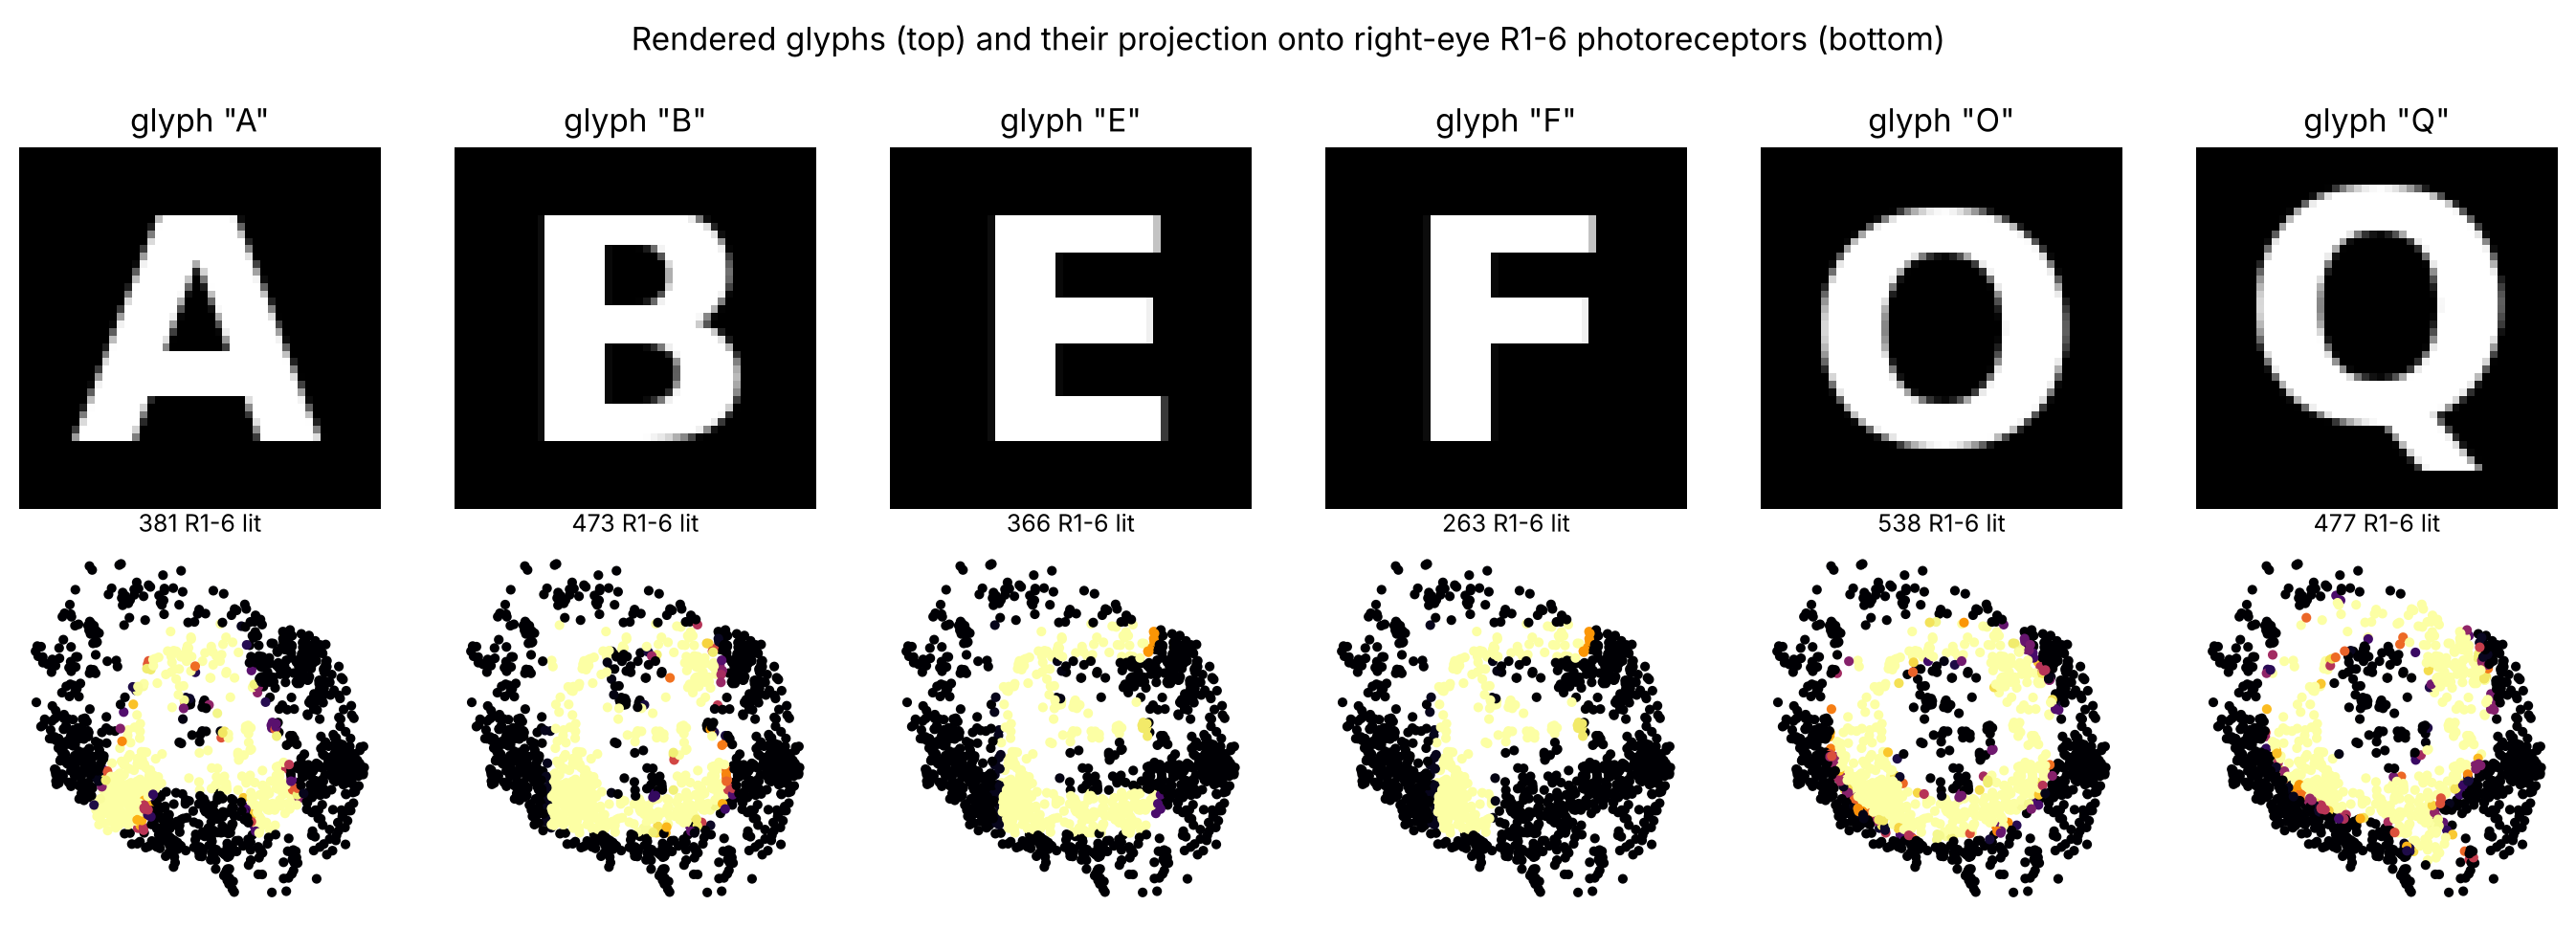

In [29]:
show = ['A', 'B', 'E', 'F', 'O', 'Q']
fig, axes = plt.subplots(2, len(show), figsize=(2.3 * len(show), 4.8))
for k, ch in enumerate(show):
    c = UPPER.index(ch)
    axes[0, k].imshow(glyphs[c], cmap='gray'); axes[0, k].set_title(f'glyph "{ch}"'); axes[0, k].axis('off')
    sc = axes[1, k].scatter(retina_uv[:, 0], 1 - retina_uv[:, 1], c=intensity[c], cmap='inferno', s=7, vmin=0, vmax=1)
    axes[1, k].set_aspect('equal'); axes[1, k].axis('off')
    axes[1, k].set_title(f'{(intensity[c] > 0.5).sum()} R1-6 lit', fontsize=9)
fig.suptitle('Rendered glyphs (top) and their projection onto right-eye R1-6 photoreceptors (bottom)', y=1.0)
plt.tight_layout(); plt.show()

## Step 23: Reservoir with photoreceptor input
Same builder as Part 3, generalised once more: the input group is now the photoreceptors, with a per-trial rate vector equal to glyph intensity × `MAX_RATE`. The real connectivity is used.

In [30]:
def build_reservoir_inputs(in_idx):
    '''Full real-connectome LIF network with a PoissonGroup wired 1:1 onto `in_idx`.'''
    neu = NeuronGroup(len(df_comp), EQS, method='linear',
                      threshold='v > v_th', reset='v = v_rst; g = 0*mV',
                      refractory='rfc', namespace=P)
    neu.v = P['v_0']; neu.g = 0*mV; neu.rfc = P['t_rfc']
    neu.rfc[in_idx] = 0*ms

    syn = Synapses(neu, neu, 'w : volt', on_pre='g += w', delay=P['t_dly'])
    syn.connect(i=pre_real, j=post_real)
    syn.w = w_real * P['w_syn']

    inp = PoissonGroup(len(in_idx), rates=0*Hz)
    syn_in = Synapses(inp, neu, on_pre='v += w_in', namespace=dict(w_in=P['w_syn'] * P['f_poi']))
    syn_in.connect(i=np.arange(len(in_idx)), j=in_idx)

    mon = SpikeMonitor(neu)
    net = Network(neu, syn, inp, syn_in, mon)
    net.store()
    return net, inp, mon


def run_block_glyph(trial_list, seed):
    np.random.seed(seed)
    net, inp, mon = build_reservoir_inputs(pr_idx)
    counts = np.zeros((len(trial_list), len(df_comp)), dtype=np.uint16)
    for n, (c, _) in enumerate(trial_list):
        net.restore()
        inp.rates = intensity[c] * MAX_RATE          # glyph brightness -> photoreceptor rate
        net.run(T_TRIAL)
        counts[n] = mon.count[:]
    return counts

t0 = time.time()
res = Parallel(n_jobs=n_workers)(delayed(run_block_glyph)(b, 2000 + i) for i, b in enumerate(blocks))
X_glyph = np.vstack(res).astype(np.float32)          # same trial order / labels `y` as Parts 2-3
print(f'{len(trial_list)} glyph trials in {time.time()-t0:.0f} s')
print(f'spikes per trial: median {np.median(X_glyph.sum(1)):,.0f}, range {X_glyph.sum(1).min():,.0f} to {X_glyph.sum(1).max():,.0f}')
print(f'neurons that fired in >=1 trial: {(X_glyph.sum(0) > 0).sum():,}  '
      f'(of which photoreceptors: {((X_glyph.sum(0) > 0) & is_pr).sum()})')

260 glyph trials in 83 s
spikes per trial: median 4,119, range 1,292 to 6,990
neurons that fired in >=1 trial: 1,570  (of which photoreceptors: 1047)


## Step 24: Readout (can downstream neurons tell the letters apart?)
Features exclude every photoreceptor (the "retina"), so the readout only sees the brain's response. Same √-transform, z-score, ridge, 5-fold CV, and shuffled-label control.

In [31]:
feat_glyph   = np.where((X_glyph.sum(0) > 0) & ~is_pr)[0]
X_down_glyph = np.sqrt(X_glyph[:, feat_glyph])

acc_by_alpha_glyph = {a: ridge_acc(X_down_glyph, y, a) for a in alphas}
best_alpha_glyph   = max(acc_by_alpha_glyph, key=acc_by_alpha_glyph.get)
acc_glyph      = acc_by_alpha_glyph[best_alpha_glyph]
acc_glyph_perm = ridge_acc(X_down_glyph, np.random.default_rng(0).permutation(y), best_alpha_glyph)
acc_retina     = ridge_acc(np.sqrt(X_glyph[:, pr_idx]), y, best_alpha_glyph)   # photoreceptors only (upper bound)

print(f'downstream (non-photoreceptor) features: {len(feat_glyph):,}')
print(f'glyph decoding, downstream neurons : {acc_glyph:.1%}   (best alpha = {best_alpha_glyph:g})')
print(f'glyph decoding, retina only        : {acc_retina:.1%}')
print(f'shuffled-label control             : {acc_glyph_perm:.1%}   (chance {1/K:.1%})')

downstream (non-photoreceptor) features: 523
glyph decoding, downstream neurons : 93.1%   (best alpha = 10000)
glyph decoding, retina only        : 100.0%
shuffled-label control             : 1.5%   (chance 3.8%)


### Confusion matrix: which letters does the brain-readout confuse?
With image input, errors should land on visually similar pairs; with Part 2's random codes they were unstructured.

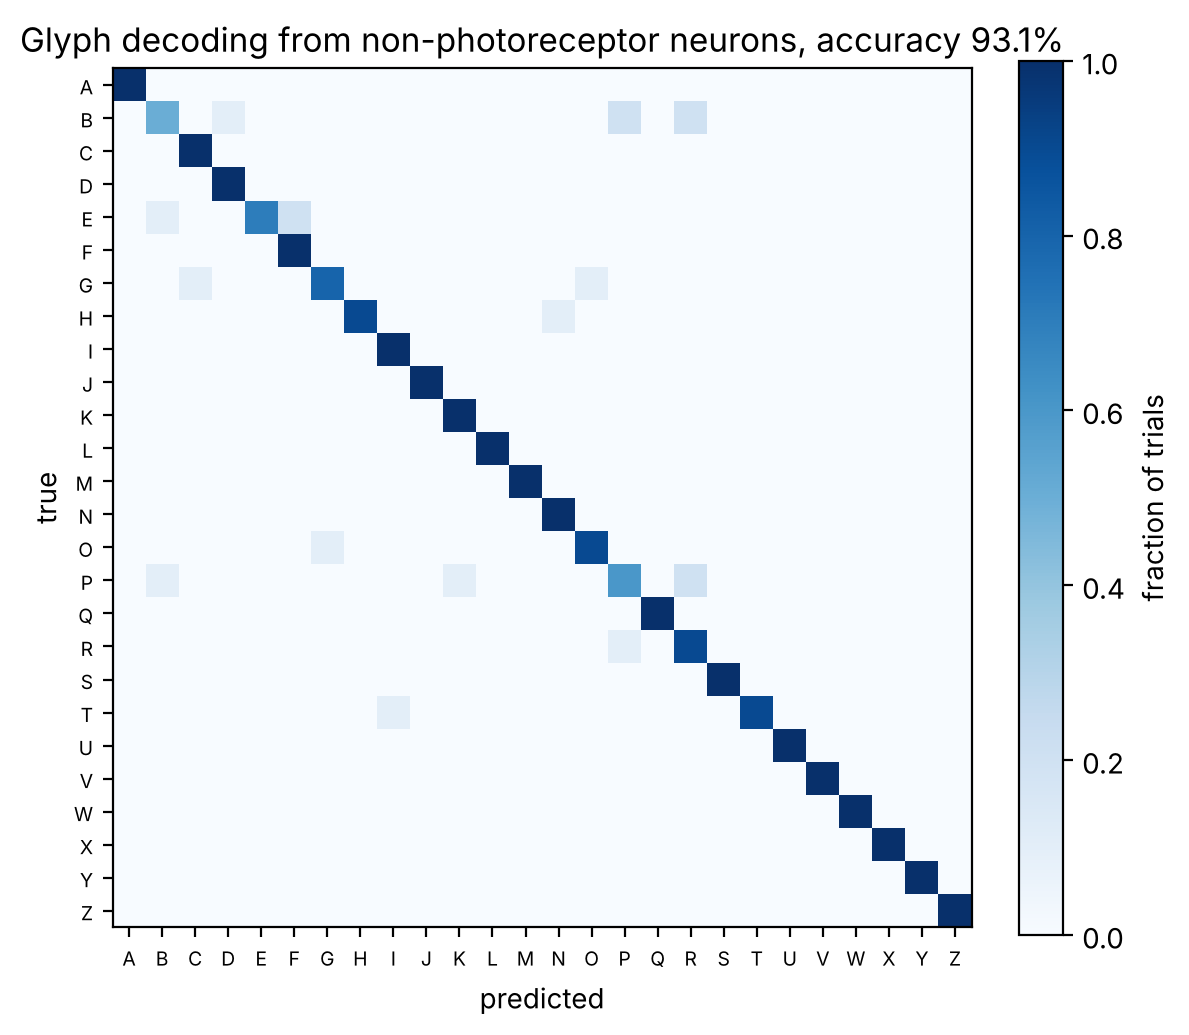

most confused pairs: [('B', 'P', np.float64(0.2)), ('B', 'R', np.float64(0.2)), ('E', 'F', np.float64(0.2)), ('P', 'R', np.float64(0.2)), ('B', 'D', np.float64(0.1)), ('E', 'B', np.float64(0.1))]


In [32]:
clf_g  = make_pipeline(StandardScaler(), RidgeClassifier(alpha=best_alpha_glyph))
y_pred_g = cross_val_predict(clf_g, X_down_glyph, y, cv=cv)
cm_g = confusion_matrix(y, y_pred_g, normalize='true')

fig, ax = plt.subplots(figsize=(6, 5.5))
im = ax.imshow(cm_g, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_xticklabels(UPPER, fontsize=7)
ax.set_yticks(range(K)); ax.set_yticklabels(UPPER, fontsize=7)
ax.set(xlabel='predicted', ylabel='true',
       title=f'Glyph decoding from non-photoreceptor neurons, accuracy {acc_glyph:.1%}')
plt.colorbar(im, ax=ax, fraction=0.046, label='fraction of trials')
plt.tight_layout(); plt.show()

off = [(UPPER[i], UPPER[j], cm_g[i, j]) for i in range(K) for j in range(K) if i != j and cm_g[i, j] > 0]
print('most confused pairs:', sorted(off, key=lambda t: -t[2])[:6])

## Step 25: Where in the brain is the letter decodable?
Group recruited non-photoreceptor neurons by FlyWire `super_class`, then fit the readout on each group alone. Optic-lobe neurons are one or two synapses from the input; central-brain neurons are the interesting case: if letters are decodable there, visual identity has crossed into the "cognitive" part of the network within 100 ms.

In [33]:
sc_map = ann.drop_duplicates('root_id').set_index('root_id')['super_class']
feat_ids = np.array([i2flyid[i] for i in feat_glyph])
feat_sc  = pd.Series(sc_map.reindex(feat_ids).fillna('unannotated').values, index=feat_glyph)

rows = []
for sc, grp in feat_sc.groupby(feat_sc):
    cols = np.searchsorted(feat_glyph, grp.index.values)
    if len(cols) < 5:
        continue
    rows.append({'super_class': sc, 'n_neurons': len(cols),
                 'accuracy': ridge_acc(X_down_glyph[:, cols], y, best_alpha_glyph)})
by_region = pd.DataFrame(rows).sort_values('n_neurons', ascending=False).reset_index(drop=True)
by_region.style.format({'accuracy': '{:.1%}'})

,super_class,n_neurons,accuracy
0,optic,370,88.1%
1,unannotated,153,87.7%


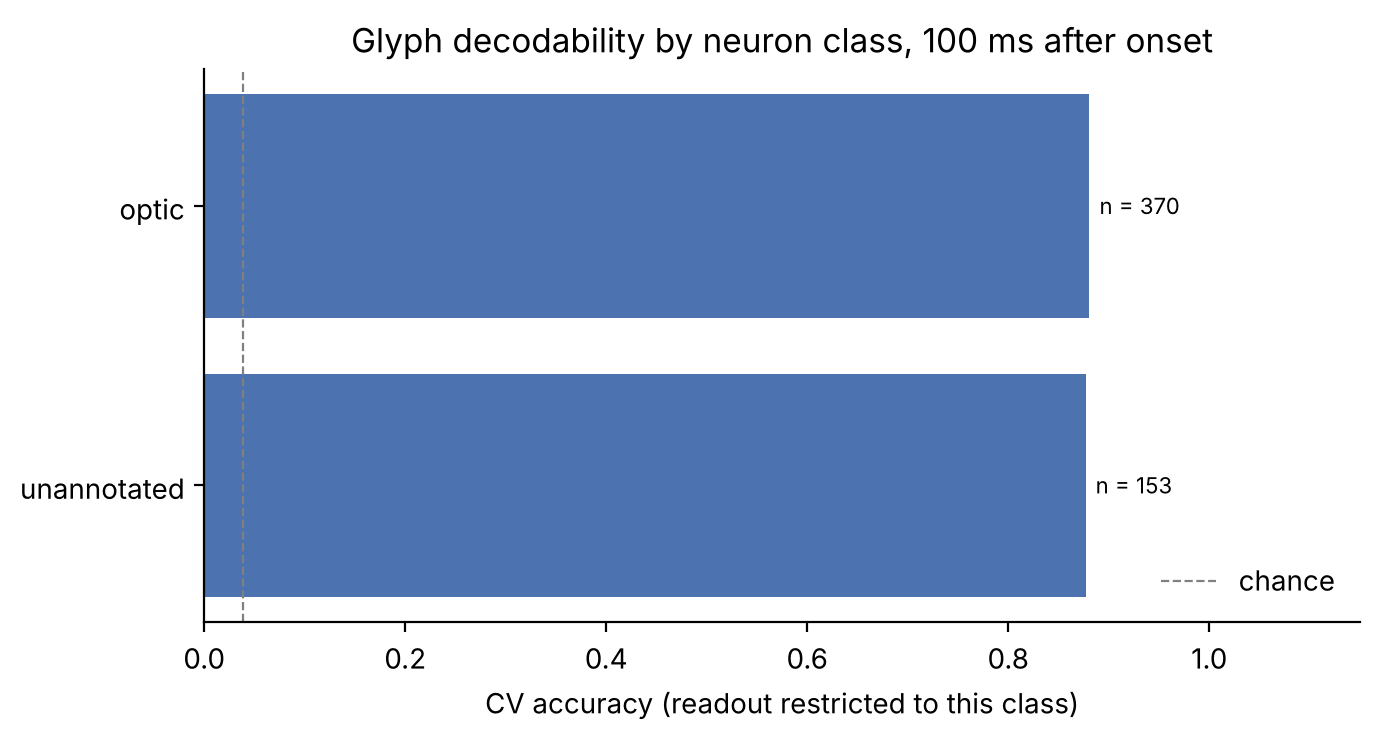

In [34]:
fig, ax = plt.subplots(figsize=(7, 3.8))
order = by_region.sort_values('accuracy', ascending=True)
ax.barh(order.super_class, order.accuracy, color='#4C72B0')
for yy, (a_, n_) in enumerate(zip(order.accuracy, order.n_neurons)):
    ax.text(a_ + 0.01, yy, f'n = {n_:,}', va='center', fontsize=8)
ax.axvline(1/K, ls='--', color='grey', lw=0.8, label='chance')
ax.set(xlim=(0, 1.15), xlabel='CV accuracy (readout restricted to this class)',
       title='Glyph decodability by neuron class, 100 ms after onset')
ax.legend(frameon=False, loc='lower right'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## Step 26: Glyphs vs. random codes: accuracy vs. readout size
Same curve as Parts 2 and 3, now with the three input schemes side by side. The glyph task has far more similar inputs (cosine ≈ 0.4 to 0.6 between letters vs ≈ 0.2 for random codes), so expect it to need more neurons for the same accuracy.

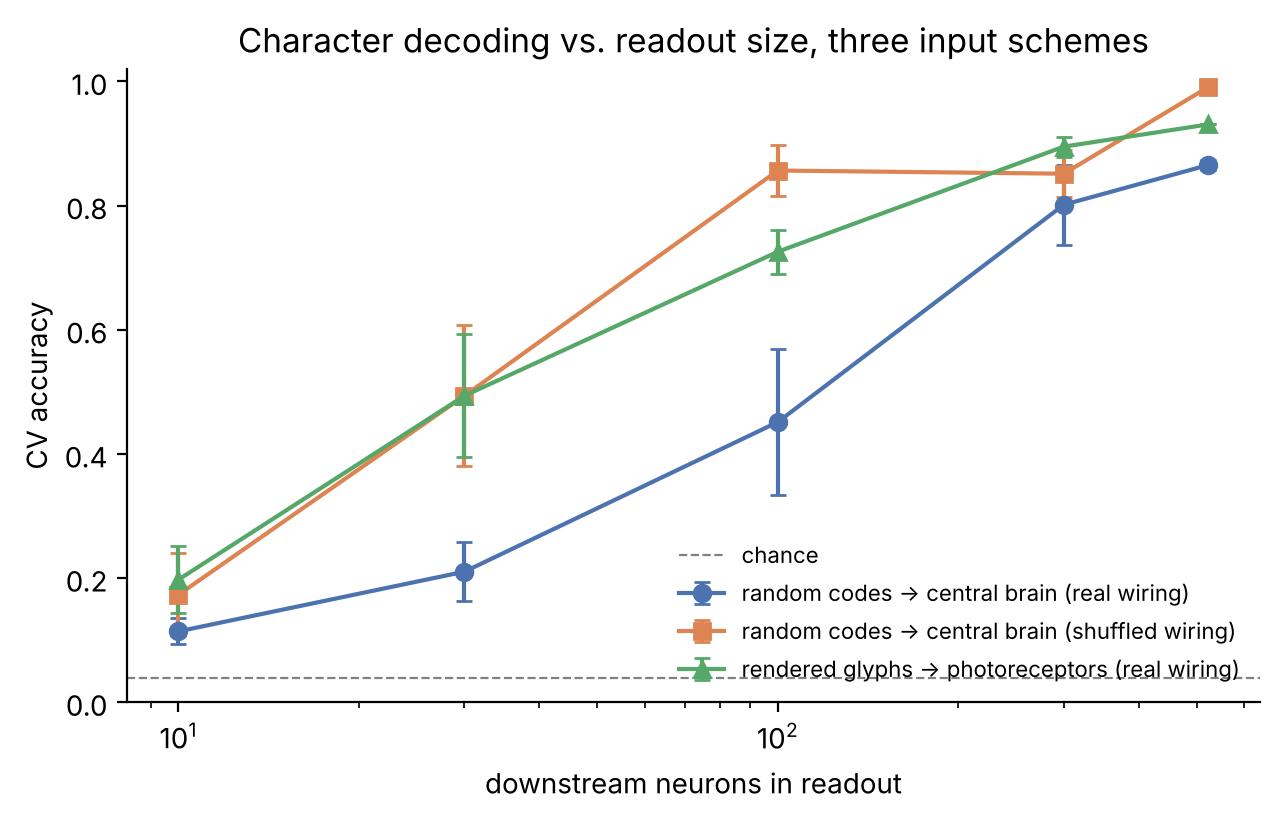

In [35]:
n_min3    = min(X_down.shape[1], X_down_shuf.shape[1], X_down_glyph.shape[1])
sizes_cmp3 = [s for s in [10, 30, 100, 300, 1000, 3000] if s <= n_min3] + [n_min3]
curve_glyph_n = acc_curve_neurons(X_down_glyph, best_alpha_glyph, sizes_cmp3)
curve_real_n3 = acc_curve_neurons(X_down,       best_alpha,       sizes_cmp3)
curve_shuf_n3 = acc_curve_neurons(X_down_shuf,  best_alpha_shuf,  sizes_cmp3)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for cv_, lab, c_, m_ in [(curve_real_n3, 'random codes → central brain (real wiring)', col['real'], 'o'),
                         (curve_shuf_n3, 'random codes → central brain (shuffled wiring)', col['shuffled'], 's'),
                         (curve_glyph_n, 'rendered glyphs → photoreceptors (real wiring)', '#55A868', '^')]:
    ax.errorbar(sizes_cmp3, cv_[:, 0], cv_[:, 1], marker=m_, capsize=3, color=c_, label=lab)
ax.axhline(1/K, ls='--', color='grey', lw=0.8, label='chance')
ax.set(xscale='log', xlabel='downstream neurons in readout', ylabel='CV accuracy', ylim=(0, 1.02),
       title='Character decoding vs. readout size, three input schemes')
ax.legend(frameon=False, fontsize=8); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## Interpretation

### What this run showed
- **The model's visual system does carry letter identity out of the retina.** A ridge readout on the 523 non-photoreceptor neurons that responded decodes 26 uppercase glyphs at **93.1 %** (shuffled labels 1.5 %, chance 3.8 %), from 100 ms of spike counts. The retina-only readout is 100 %, as it must be, because the photoreceptor pattern *is* the image.
- **The errors are visual.** Confusions are B↔P↔R, E↔F, B↔D: letters that share most of their lit pixels (mean cosine similarity between letter patterns is 0.56, with H/N at 0.94). In Part 2, with random codes, errors were unstructured. The readout is therefore operating on image structure, not on the number of lit inputs.
- **The letter does not reach the central brain in 100 ms.** Every responding non-photoreceptor neuron is `optic` (370, 88 % accuracy alone) or `unannotated` (153, 88 %). Zero `central` neurons fired in any trial. So in this model, "reading" stops in the lamina/medulla. Three non-exclusive reasons: (i) 100 ms is short for a 4 to 5 synapse path with ~37 ms per-stage latencies (recall the GRN → MN9 latency in Part 1); (ii) the model's photoreceptor neurotransmitter sign is half wrong, so the first synapse is weakened; (iii) only ~1,300 of ~6,000 right-eye R1-6 cells exist in v630, so the drive into each lamina cartridge is sparse. A longer window and a corrected photoreceptor sign are the first two things to try.
- **Compared with random codes (Step 26 figure):** the glyph task recruits far fewer downstream neurons (523 vs ~9,000) yet reaches high accuracy with a few hundred of them, because the visual system is a dense, retinotopic, nearly feed-forward stage, a very different regime from the sparse central-brain spread in Part 2.

### General guide
- **If downstream accuracy is high and the shuffled-label control is at chance**, the model's visual system propagates a letter-specific response out of the retina within the window, and a linear readout can recover the glyph identity, with every caveat above about what "reads" means.
- **The by-class breakdown answers the propagation question.** High accuracy in `optic` neurons is expected (they are the next synapse). Central-brain accuracy well above chance means the information crossed the optic lobe → central brain boundary; absence of central-brain activity (as here) means it hasn't in the window given.
- **What would make this a real experiment rather than a demo:** fix photoreceptor sign to inhibitory (histamine) and re-run; lengthen `T_TRIAL` to 200 to 300 ms and track when central neurons first fire; use the published FlyWire eye map instead of a PCA flattening so letters are upright in the fly's frame; test generalisation across fonts (train on one font, test on another, which is the question a reservoir cannot answer by memorising input patterns); and run the Part 3 degree-preserving shuffle with photoreceptor input.
- **Male CNS:** the male CNS dataset includes the optic lobes and photoreceptors too; the recipe (select R1-6, flatten positions, render, sample) carries over, and a proper eye map is more likely to exist for it.